# Leakage-Aware Machine Learning for Primary vs Recurrent Glioblastoma Classification Using Single-Cell Transcriptomic Data
**Maryam Zafar · 25i-8033 · MS Data Science Semester Project · GSE174554 (snRNA-seq)**

**Fixed research questions (unchanged):**
- **RQ1:** Can classical ML distinguish primary versus recurrent GBM nuclei using transcriptomic profiles?
- **RQ2:** How does performance change from cell-level to patient-held-out cross-validation?
- **RQ3:** Which genes are stable across patient-held-out folds, and which biological processes are enriched among those exploratory features?

This notebook retains the original research questions and classical ML comparison. It distinguishes the **legacy global-HVG analysis** (sensitivity/exploratory) from the **fold-internal-HVG analysis** (primary validation estimate).

| Part | What happens |
|---|---|
| 1–2 | Setup, expression loading, metadata and cohort audit |
| 3 | Tumor-specimen selection, QC, normalization and exploratory global HVGs |
| 4 | EDA: patient/specimen contribution and expression structure |
| 5–6 | Experiment A: cell-level CV; Experiment B: patient-held-out CV |
| 7 | Exploratory gene stability, SHAP and pathway enrichment |
| 8 | Additional confounding, pseudobulk, leakage-ladder and uncertainty analyses |
| 9 | Added analysis: fold-internal gene filtering/HVG selection, grouped inner tuning, label-shuffle control, specimen-level metrics and reproducibility audit |

**Run order:** run top-to-bottom. The original global-HVG results are retained for comparison; do not describe them as fully leakage-free. The added fold-internal analysis re-fits gene filtering, HVG selection and scaling using training folds only. It is the preferred within-cohort estimate for unseen-patient generalization. No batch correction is applied because the notebook does not establish a reliable sequencing-batch field.


## 1. Setup

In [3]:
!pip -q install "pandas<2.4" scanpy anndata umap-learn xgboost shap gprofiler-official pyreadr openpyxl tqdm GEOparse

In [4]:
import os, re, glob, gc, json, warnings, random, itertools
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt, seaborn as sns
import scanpy as sc, anndata as ad
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, balanced_accuracy_score,
                             recall_score, precision_score, accuracy_score, silhouette_score, roc_curve)
from sklearn.neighbors import NearestNeighbors
from xgboost import XGBClassifier
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sc.settings.verbosity = 1
sns.set_theme(style="whitegrid", context="notebook")
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Running in Colab: True


### Configuration
Edit only this cell. `None` means "auto-detect". Everything is explained in the comments.

In [5]:
# ============================ CONFIG ============================
USE_SYNTHETIC_DEMO = False      # True = run on fake data just to test the pipeline

# ---- Paths (Google Drive in Colab) ----
DRIVE_ROOT    = "/content/drive/MyDrive/DSTT_GBM"
DATA_PATH     = "/content/gse174554_raw"       # folder where GSE174554_RAW.tar is extracted (extract cell must run first)
METADATA_PATH = f"{DRIVE_ROOT}/data/GSE174554_Tumor_normal_metadata.txt.gz"
OUT_DIR       = f"{DRIVE_ROOT}/GBM_leakage_project_outputs"

# ---- Expression file layout (only used for csv/tsv expression tables) ----
EXPR_ORIENTATION = "auto"       # "auto" | "genes_x_cells" | "cells_x_genes"

# ---- Metadata columns (None = auto-detect; override if the printout in Part 2 is wrong) ----
PATIENT_COL    = None           # patient identifier  -> used ONLY as the CV grouping variable, never as a feature
PATIENT_REGEX  = None           # optional: derive patient from the sample name, e.g. r"^([A-Za-z]*\d+)" (first capture group)
SAMPLE_COL     = None           # tumour/sample identifier (one per specimen)
STATUS_COL     = None           # Primary vs Recurrent column
STATUS_MAP     = {}             # manual mapping if auto fails, e.g. {"UP": "Primary", "R1": "Recurrent"}
MALIGNANT_COL  = None           # column with malignant / non-malignant (or cell-type) annotation
MALIGNANT_VALUES = None         # list of values in MALIGNANT_COL that mean malignant, e.g. ["Tumor"]. None = auto
META_KEY_COL   = None           # metadata column holding cell barcodes (None = auto)

# ---- Data handling ----
POSITIVE_LABEL        = "Recurrent"
NORMALIZATION         = "auto"  # "auto" | "raw_counts" | "linear_normalized" | "already_log"
MIN_CELLS_PER_SAMPLE  = 30      # drop samples with fewer malignant cells
MAX_CELLS_PER_SAMPLE  = 300     # balanced subsampling cap per sample (None = keep all; needs lots of RAM/time)
N_HVG                 = 2000

# ---- Experiments ----
SEED        = 42
N_SPLITS    = 5
N_REPEATS   = 2                 # repeated CV with different seeds (more folds -> more stable gene statistics)
MODELS_TO_RUN = ["LogReg", "ElasticNet", "RandomForest", "XGBoost"]
TUNE        = False             # True = small inner-CV hyper-parameter search on TRAINING data only (slower)

# ---- Feature stability / interpretation ----
TOP_K_GENES      = 100          # a gene is "important" in a fold if it is in that fold's top-K
STABLE_MIN_FREQ  = 0.6          # stable = important in >= 60% of patient-held-out folds
RUN_SHAP         = True
RUN_ENRICHMENT   = True
# =================================================================

random.seed(SEED); np.random.seed(SEED)
if IN_COLAB and not USE_SYNTHETIC_DEMO:
    from google.colab import drive
    drive.mount("/content/drive")
OUT_DIR = Path(OUT_DIR if not USE_SYNTHETIC_DEMO else "demo_outputs"); FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight"); plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Load data and audit metadata
The loader handles the usual GEO formats (h5ad, csv/tsv tables, 10x `matrix.mtx` folders incl. per-sample GEO RAW files, `.rds/.RData` data frames).

In [6]:
# ---------------------------- loader helpers ----------------------------
def _looks_like_barcodes(labels):
    s = pd.Index(labels[:200]).astype(str)
    return np.mean([bool(re.search(r"[ACGT]{12,}", x)) for x in s]) > 0.5

def read_table_any(path, index_col=None, **kw):
    pl = str(path).lower()
    if pl.endswith((".xlsx", ".xls")): return pd.read_excel(path, index_col=index_col, **kw)
    if pl.endswith(".parquet"):        return pd.read_parquet(path)
    if pl.endswith((".tsv", ".tsv.gz", ".txt", ".txt.gz")): return pd.read_csv(path, sep="\t", index_col=index_col, **kw)
    return pd.read_csv(path, index_col=index_col, **kw)

def df_to_adata(df, orientation="auto"):
    if orientation == "auto":
        if _looks_like_barcodes(df.index):     orientation = "cells_x_genes"
        elif _looks_like_barcodes(df.columns): orientation = "genes_x_cells"
        else:                                  orientation = "genes_x_cells"
    print("expression table orientation:", orientation)
    if orientation == "genes_x_cells": df = df.T
    a = ad.AnnData(X=sp.csr_matrix(df.values.astype(np.float32)),
                   obs=pd.DataFrame(index=df.index.astype(str)), var=pd.DataFrame(index=df.columns.astype(str)))
    a.var_names_make_unique(); return a

def load_10x_folder(d):
    mtx = sorted(glob.glob(os.path.join(d, "*matrix.mtx*")))
    if len(mtx) == 1 and os.path.basename(mtx[0]).startswith("matrix.mtx"):
        a = sc.read_10x_mtx(d, var_names="gene_symbols"); a.var_names_make_unique(); return a
    parts = []
    for m in tqdm(mtx, desc="10x samples"):
        prefix = os.path.basename(m)[: os.path.basename(m).rfind("matrix.mtx")]
        a = sc.read_10x_mtx(d, prefix=prefix, var_names="gene_symbols"); a.var_names_make_unique()
        name = prefix.strip("_.-")
        a.obs["sample"] = name; a.obs["barcode_raw"] = a.obs_names.astype(str)
        a.obs_names = name + "_" + a.obs_names.astype(str); parts.append(a)
    return ad.concat(parts, join="inner")

def load_expression(path):
    p = Path(path); pl = str(p).lower()
    if p.is_dir():
        if glob.glob(str(p / "*matrix.mtx*")): return load_10x_folder(str(p))
        h5 = sorted(p.glob("*.h5ad"))
        if h5: return sc.read_h5ad(h5[0])
        tabs = [f for f in p.iterdir() if f.is_file() and re.search(r"\.(csv|tsv|txt|rds|rdata|rda)(\.gz)?$", f.name.lower())
                and not re.search(r"meta|annot|clinical|sample", f.name.lower())]
        if not tabs: raise FileNotFoundError("No recognisable expression file in DATA_PATH. Point DATA_PATH at the file itself.")
        tabs.sort(key=lambda f: f.stat().st_size, reverse=True)
        print("using expression file:", tabs[0].name); return load_expression(tabs[0])
    if pl.endswith(".h5ad"): return sc.read_h5ad(p)
    if pl.endswith(".h5"):   return sc.read_10x_h5(p)
    if pl.endswith((".rds", ".rdata", ".rda")):
        import pyreadr
        obj = pyreadr.read_r(str(p)); df = next(iter(obj.values()))
        if not isinstance(df, pd.DataFrame):
            raise ValueError("R object is not a plain data.frame (e.g. a Seurat/dgCMatrix). In R run: "
                             "Matrix::writeMM(obj, 'matrix.mtx'); write.csv(meta, 'metadata.csv') and use those files.")
        return df_to_adata(df, EXPR_ORIENTATION)
    if re.search(r"\.(csv|tsv|txt)(\.gz)?$", pl):
        print("reading table (can take a while for big files) ...")
        return df_to_adata(read_table_any(p, index_col=0), EXPR_ORIENTATION)
    raise ValueError(f"Unsupported expression file: {p}")

def find_metadata(path):
    p = Path(path)
    if not p.is_dir(): p = p.parent
    cands = [f for f in p.rglob("*") if f.is_file() and re.search(r"(meta|annot|clinical|cell_info|cells)", f.name.lower())
             and re.search(r"\.(csv|tsv|txt|xlsx|xls)(\.gz)?$", f.name.lower())]
    cands.sort(key=lambda f: ("meta" not in f.name.lower(), -f.stat().st_size))
    return str(cands[0]) if cands else None

# ---------------------------- metadata merge ----------------------------
_VARIANTS = {
    "identity":     lambda s: s,
    "strip_-N":     lambda s: s.str.replace(r"-\d+$", "", regex=True),
    "lowercase":    lambda s: s.str.lower(),
    "barcode_core": lambda s: s.str.extract(r"([ACGT]{12,})", expand=False),
}

def attach_metadata(adata, meta):
    obs_ids = pd.Series(adata.obs_names.astype(str), index=adata.obs_names)
    cols = [META_KEY_COL] if META_KEY_COL else [c for c in meta.columns if meta[c].dtype == object or str(meta[c].dtype).startswith("str")]
    best = (0, None, None)
    for c in cols:
        mk = meta[c].astype(str)
        for vn, fn in _VARIANTS.items():
            ot, mt = fn(obs_ids), fn(mk).dropna()
            if vn == "barcode_core" and (ot.dropna().duplicated().mean() > 0.01 or mt.duplicated().mean() > 0.01): continue
            frac = ot.isin(set(mt)).mean()
            if frac > best[0]: best = (frac, c, vn)
    frac, col, vn = best
    print(f"best metadata key: column={col!r} transform={vn!r} -> matches {frac:.1%} of cells")
    if col is None or frac < 0.5:
        print("expression cell IDs (first 3):", list(obs_ids.iloc[:3]));
        print("metadata columns:", list(meta.columns)[:15]); print(meta.head(3))
        raise ValueError("Could not link metadata to cells. Set META_KEY_COL (and check the IDs printed above).")
    fn = _VARIANTS[vn]
    m = meta.copy(); m["_key"] = fn(m[col].astype(str)); m = m.dropna(subset=["_key"]).drop_duplicates("_key").set_index("_key")
    okey = fn(obs_ids)
    keep = okey.isin(m.index).values
    print(f"cells with metadata: {keep.sum():,} / {len(keep):,} (others dropped)")
    adata = adata[keep].copy(); okey = okey[keep]
    mm = m.loc[okey.values].copy(); mm.index = adata.obs_names
    for c in mm.columns:
        adata.obs[c if c not in adata.obs.columns else f"meta_{c}"] = mm[c].values
    return adata

# ---------------------------- synthetic demo data ----------------------------
def make_synthetic(n_patients=24, cells_per_sample=200, n_genes=3000, seed=0):
    rng = np.random.RandomState(seed)
    genes = [f"GENE{i}" for i in range(n_genes)]
    base = np.log(rng.gamma(0.6, 1.0, n_genes) + 0.05)
    st_genes = rng.choice(n_genes, 60, replace=False); st_eff = rng.normal(0, 0.5, 60)
    blocks, obs = [], []
    for p in range(n_patients):
        pat_eff = rng.normal(0, 0.8, n_genes)
        for status in ["Primary", "Recurrent"]:
            lam = np.exp(base + pat_eff)
            if status == "Recurrent": lam[st_genes] *= np.exp(st_eff)
            n = cells_per_sample + rng.randint(-40, 40)
            X = rng.poisson(lam[None, :] * rng.gamma(5, 0.2, size=(n, 1))).astype(np.float32)
            blocks.append(sp.csr_matrix(X))
            for i in range(n):
                obs.append(dict(patient=f"PT{p:02d}", sample=f"PT{p:02d}_{status[:3]}", timepoint=status,
                                cell_type="Malignant" if rng.rand() < 0.85 else "Myeloid"))
    obs = pd.DataFrame(obs); obs.index = [f"cell{i}" for i in range(len(obs))]
    return ad.AnnData(X=sp.vstack(blocks).tocsr(), obs=obs, var=pd.DataFrame(index=genes))

### Load nuclei tagged Tumor + specimen labels

The source `Tumor/Normal` metadata is barcode/cell-level (it assigns a Tumor or Normal flag to individual barcodes). The loader filters to barcodes tagged `Tumor` and then assigns the constant string `"Tumor"` to `Tumor_Normal_annotation` for every retained row. Thus the retained column is constant **by construction** and is not an independent malignant-cell annotation. Tumor/Normal is also not synonymous with malignant/non-malignant. Unless the source provides a separate author cell-type or CNV-based malignancy call, describe the input as **nuclei tagged Tumor from tumor specimens**, not confirmed malignant cells. Primary/Recurrent and patient (`pair#`) labels come from GEO specimen metadata.


In [7]:
LOAD_CAP_PER_SAMPLE = 600     # max tumour cells read per matrix file (RAM safety)

if USE_SYNTHETIC_DEMO:
    adata = make_synthetic(seed=SEED)
else:
    import GEOparse, tarfile, gzip

    # ---------- 0. extract the RAW tar (skipped if already extracted in this session) ----------
    TAR = f"{DRIVE_ROOT}/data/GSE174554_RAW.tar"
    if not glob.glob(f"{DATA_PATH}/*matrix.mtx*"):
        os.makedirs(DATA_PATH, exist_ok=True)
        with tarfile.open(TAR) as t: t.extractall(DATA_PATH)
    print(len(os.listdir(DATA_PATH)), "files in", DATA_PATH)

    # ---------- 1. cell metadata (SPACE separated) -> tumour cells only ----------
    meta = pd.read_csv(METADATA_PATH, sep=r"\s+", compression="infer")
    meta.columns = ["cell_id", "tumor_normal"]
    print(meta.tumor_normal.value_counts())
    tumor_ids = set(meta.loc[meta.tumor_normal == "Tumor", "cell_id"].astype(str))
    tumor_ids = {re.sub(r"[.\-]\d+$", "", x) for x in tumor_ids}   # normalise metadata IDs: strip trailing ".1" / "-1"

    # ---------- 2. sample table from GEO: progression (status) + pair# (patient) ----------
    gse = GEOparse.get_GEO("GSE174554", destdir="/content/geo", silent=True)
    rows = []
    for gsm_id, gsm in gse.gsms.items():
        md = gsm.metadata
        title = "; ".join(md.get("title", []))
        ch = {}
        for s in md.get("characteristics_ch1", []):
            if ":" in s:
                k, v = s.split(":", 1); ch[k.strip().lower()] = v.strip()
        m = re.search(r"(SF\d+)", title)
        rows.append(dict(gsm=gsm_id, title=title, sf=m.group(1) if m else None,
                         status=ch.get("progression"), pair=ch.get("pair#")))
    geo = pd.DataFrame(rows)
    N_GEO_SPECIMENS_ALL = int(len(geo))
    geo = geo[geo.status.isin(["Primary", "Recurrent"]) & ~geo.title.str.contains("ATAC", case=False)].copy()
    N_GEO_STATUS_SPECIMENS = int(len(geo))

    def patient_id(r):
        p = str(r.pair).strip().lstrip("#")
        return f"pair{p}" if p.isdigit() else f"solo_{r.sf}"      # unpaired tumour = its own patient
    geo["patient"] = geo.apply(patient_id, axis=1)
    GEO = geo.set_index("gsm")
    print(f"{len(GEO)} snRNA specimens with status | patients: {GEO.patient.nunique()}")
    print(GEO.status.value_counts().to_dict())
    nst = GEO.groupby("patient").status.nunique()
    print("patients with both Primary+Recurrent:", int((nst == 2).sum()), "| patients with one status only:", int((nst == 1).sum()))

    # ---------- 3. tolerant .mtx reader ----------
    def _mtx_header(path):
        with gzip.open(path, "rt") as fh:
            n = 0
            for line in fh:
                n += 1
                if line.startswith("%"): continue
                nr, nc, nnz = map(int, line.split()[:3]); return nr, nc, nnz, n

    def read_mtx_selected(path, sel, n_genes, n_bcs):
        nr, nc, nnz, nskip = _mtx_header(path)
        if   (nr, nc) == (n_genes, n_bcs): cell_axis = 1          # genes x cells (10x standard)
        elif (nr, nc) == (n_bcs, n_genes): cell_axis = 0
        else: raise ValueError(f"shape {(nr, nc)} vs genes={n_genes}, barcodes={n_bcs}")
        lookup = np.full((nc if cell_axis == 1 else nr) + 1, -1, dtype=np.int64)
        lookup[sel + 1] = np.arange(len(sel))                     # mtx is 1-based
        R, C, V = [], [], []
        # 4th column "extra" absorbs the odd 4-field line; it is ignored
        for ch in pd.read_csv(path, sep=r"\s+", skiprows=nskip, header=None, names=["i", "j", "v", "extra"],
                              dtype={"i": np.int64, "j": np.int64, "v": np.float32}, chunksize=4_000_000):
            i, j, v = ch["i"].values, ch["j"].values, ch["v"].values
            c, g = (j, i) if cell_axis == 1 else (i, j)
            newc = lookup[c]; k = newc >= 0
            R.append(newc[k]); C.append(g[k] - 1); V.append(v[k])
        return sp.csr_matrix((np.concatenate(V), (np.concatenate(R), np.concatenate(C))), shape=(len(sel), n_genes))

    # ---------- 4. load every specimen ----------
    rng = np.random.RandomState(SEED); parts = []; log = []; failed = []
    for m in tqdm(sorted(glob.glob(f"{DATA_PATH}/*matrix.mtx*")), desc="samples"):
        base = os.path.basename(m); gsm = base.split("_")[0]
        if gsm not in GEO.index: continue                          # snATAC / non-specimen files
        info = GEO.loc[gsm]; prefix = base[: base.rfind("matrix.mtx")]
        bc_f = glob.glob(os.path.join(DATA_PATH, prefix + "barcodes*"))
        ft_f = glob.glob(os.path.join(DATA_PATH, prefix + "features*")) or glob.glob(os.path.join(DATA_PATH, prefix + "genes*"))
        if not bc_f or not ft_f: print("missing barcodes/features for", base); continue
        bcs = pd.read_csv(bc_f[0], sep="\t", header=None)[0].astype(str).str.replace(r"-\d+$", "", regex=True).values
        f = pd.read_csv(ft_f[0], sep="\t", header=None); genes_f = (f[1] if f.shape[1] > 1 else f[0]).astype(str).values
        # key = SFid_barcode (sample name from the GEO title, or from the file name as fallback e.g. SF9715v2)
        file_sf = re.search(r"_(SF\w+?)(?:_batch\d+)?_$", prefix)
        generic = prefix.split("_", 1)[1].strip("_") if "_" in prefix else prefix.strip("_")   # e.g. T5224_3days_treated
        cands = [x for x in dict.fromkeys([info.sf, file_sf.group(1) if file_sf else None, generic]) if x]
        hit = {s: pd.Series([f"{s}_{b}" for b in bcs]).isin(tumor_ids).values for s in cands}
        if not any(h.any() for h in hit.values()):
            print("skip (no tumour cells in metadata):", base); log.append((base, len(bcs), 0, None)); continue
        best_sf = max(cands, key=lambda s: hit[s].mean())
        sel = np.where(hit[best_sf])[0]
        log.append((base, len(bcs), len(sel), best_sf))
        if len(sel) == 0: continue
        if len(sel) > LOAD_CAP_PER_SAMPLE: sel = np.sort(rng.choice(sel, LOAD_CAP_PER_SAMPLE, replace=False))
        try:
            X = read_mtx_selected(m, sel, len(genes_f), len(bcs))
        except Exception as e:
            print("!! FAILED to read", base, "->", repr(e)[:150]); failed.append(base); continue
        a = ad.AnnData(X=X, obs=pd.DataFrame({"sample": f"{info.sf}", "gsm": gsm, "patient": info.patient, "status": info.status,
                                              "Tumor_Normal_annotation": "Tumor"}, index=[f"{gsm}_{b}" for b in bcs[sel]]),
                       var=pd.DataFrame(index=genes_f))
        a.var_names_make_unique(); parts.append(a); del X, a; gc.collect()

    display(pd.DataFrame(log, columns=["file", "n_barcodes", "n_tumour_in_meta", "key_prefix"]).head(15))
    print(f"samples loaded: {len(parts)} | failed: {len(failed)} {failed}")
    assert len(parts) > 0, "No samples loaded - check the log above (n_tumour_in_meta == 0 means the barcode key format is off)."
    adata = ad.concat(parts, join="inner"); del parts; gc.collect()
    LOADED_CELLS_BEFORE_QC = int(adata.n_obs)
    LOADED_SPECIMENS_BEFORE_QC = int(adata.obs["gsm"].nunique()) if "gsm" in adata.obs else int(adata.obs["sample"].nunique())
    LOADED_PATIENTS_BEFORE_QC = int(adata.obs["patient"].nunique())
    LOADED_STATUS_COUNTS = adata.obs.groupby("status").size().to_dict()
    print(adata.obs.groupby("status").size())

    # ---------- 5. tell the downstream cells which columns to use ----------
    PATIENT_COL, SAMPLE_COL, STATUS_COL = "patient", "sample", "status"
    MALIGNANT_COL, MALIGNANT_VALUES = "Tumor_Normal_annotation", ["Tumor"]

adata.obs_names = adata.obs_names.astype(str); adata.var_names_make_unique()
print(adata)
display(adata.obs.head())

329 files in /content/gse174554_raw
tumor_normal
Normal    127515
Tumor     126773
Name: count, dtype: int64
103 snRNA specimens with status | patients: 57
{'Recurrent': 56, 'Primary': 47}
patients with both Primary+Recurrent: 30 | patients with one status only: 27


samples:   0%|          | 0/103 [00:00<?, ?it/s]

skip (no tumour cells in metadata): GSM5319505_SF10857_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319510_SF11815_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319511_SF11916_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319522_SF3996_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319523_SF4209_batch2_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319524_SF4810_batch2_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319531_SF9372_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319535_SF10433_batch2_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319540_SF11720_batch2_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319555_SF7025_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319557_SF7388_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319572_SF4324_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319573_SF11981_matrix.mtx.gz
skip (no tumour cells in metadata): GSM5319576_SF4449_batch2_matrix.mtx.gz
skip (n

,file,n_barcodes,n_tumour_in_meta,key_prefix
0,GSM5319503_SF10099_batch2_matrix.mtx.gz,117,1,SF10099
1,GSM5319503_SF10099_matrix.mtx.gz,568,449,SF10099
2,GSM5319504_SF10432_matrix.mtx.gz,994,877,SF10432
3,GSM5319505_SF10857_matrix.mtx.gz,2624,0,None
4,GSM5319506_SF11082_matrix.mtx.gz,4134,4023,SF11082
5,GSM5319507_SF11344_matrix.mtx.gz,5783,589,SF11344
6,GSM5319508_SF11587_matrix.mtx.gz,1300,1253,SF11587
7,GSM5319509_SF11780_matrix.mtx.gz,6686,6470,SF11780
8,GSM5319510_SF11815_matrix.mtx.gz,3705,0,None
9,GSM5319511_SF11916_matrix.mtx.gz,1332,0,None


samples loaded: 75 | failed: 0 []
status
Primary      12371
Recurrent    22301
dtype: int64
AnnData object with n_obs × n_vars = 34672 × 33694
    obs: 'sample', 'gsm', 'patient', 'status', 'Tumor_Normal_annotation'
    layers: None (.X)


,sample,gsm,patient,status,Tumor_Normal_annotation
GSM5319503_CCCGGAAGTGGACTGA,SF10099,GSM5319503,pair9,Primary,Tumor
GSM5319503_AAACGCTCAATTGCTG,SF10099,GSM5319503,pair9,Primary,Tumor
GSM5319503_AAAGGTAAGGATAATC,SF10099,GSM5319503,pair9,Primary,Tumor
GSM5319503_AAAGGTATCTAAGGAA,SF10099,GSM5319503,pair9,Primary,Tumor
GSM5319503_AAAGTGAAGCGGTATG,SF10099,GSM5319503,pair9,Primary,Tumor


In [8]:
print(sorted(set(["SF2777","SF4849","SF10108","SF10514","SF1343","SF2628"]) - set(adata.obs["sample"])), "<- should be []")
print(adata.obs.groupby("status")["sample"].nunique().to_dict(), "specimens |", adata.obs["patient"].nunique(), "patients")
print("patients with both statuses:", int((adata.obs.groupby("patient")["status"].nunique() == 2).sum()))

[] <- should be []
{'Primary': 27, 'Recurrent': 40} specimens | 46 patients
patients with both statuses: 20


In [9]:
# ---------------- metadata audit: what columns exist and what do they contain? ----------------
audit = pd.DataFrame({"n_unique": adata.obs.nunique(), "dtype": adata.obs.dtypes.astype(str),
                      "example_values": [", ".join(map(str, adata.obs[c].dropna().unique()[:5])) for c in adata.obs.columns]})
display(audit)
print("missing values per column:"); print(adata.obs.isna().sum()[lambda s: s > 0])

,n_unique,dtype,example_values
sample,67,object,"SF10099, SF10432, SF11082, SF11344, SF11587"
gsm,70,object,"GSM5319503, GSM5319504, GSM5319506, GSM5319507..."
patient,46,object,"pair9, pair19, pair28, pair40, pair23"
status,2,object,"Primary, Recurrent"
Tumor_Normal_annotation,1,object,Tumor


missing values per column:
Series([], dtype: int64)


In [10]:
# ---------------- auto-detect patient / sample / status / malignant columns ----------------
def guess_col(obs, keys, card=(2, 10**7), exclude=()):
    best = None
    for c in obs.columns:
        if c in exclude: continue
        n = obs[c].nunique()
        if not (card[0] <= n <= card[1]): continue
        name = c.lower()
        for i, k in enumerate(keys):
            if k in name:
                if best is None or i < best[0]: best = (i, c)
                break
    return best[1] if best else None

def map_status_value(v):
    if v in STATUS_MAP: return STATUS_MAP[v]
    s = str(v).lower()
    if re.search(r"recur|relaps|\brec\b|[_\-\.]rec|rec$|post[-_ ]?(treat|therapy)|second", s): return "Recurrent"
    if re.search(r"prim|initial|pre[-_ ]?(treat|therapy)|newly|diagnos|[_\-\.]pri|\bpri\b|pri$|untreated", s): return "Primary"
    return None

def guess_status_col(obs, exclude=()):
    keys = ["recurr", "status", "timepoint", "time", "condition", "stage", "group", "treatment", "type", "sample"]
    cands = sorted([c for c in obs.columns if c not in exclude and 2 <= obs[c].nunique() <= 200],
                   key=lambda c: min([i for i, k in enumerate(keys) if k in c.lower()] or [99]))
    for c in cands:
        mapped = obs[c].map(map_status_value)
        if mapped.notna().mean() > 0.99 and mapped.nunique() == 2: return c
    return None

NEG_WORDS = ["non", "normal", "healthy", "not "]
POS_WORDS = ["malignant", "neoplastic", "tumor", "tumour", "gbm", "like"]
def is_malignant_value(v):
    s = str(v).lower()
    return any(w in s for w in POS_WORDS) and not any(w in s for w in NEG_WORDS)

obs = adata.obs
sample_col = SAMPLE_COL or guess_col(obs, ["sample", "specimen", "orig.ident", "library", "biopsy"], card=(2, 500))
if PATIENT_REGEX and (sample_col or PATIENT_COL is None):
    base_col = sample_col
    obs["patient_derived"] = obs[base_col].astype(str).str.extract(PATIENT_REGEX, expand=False)
    patient_col = "patient_derived"
else:
    patient_col = PATIENT_COL or guess_col(obs, ["patient", "subject", "donor", "individual", "pid", "case"], card=(2, 500), exclude=[sample_col])
status_col = STATUS_COL or guess_status_col(obs, exclude=[patient_col] if patient_col else [])
mal_col = MALIGNANT_COL
if mal_col is None:
    for c in sorted(obs.columns, key=lambda c: min([i for i, k in enumerate(["malignan", "neoplas", "tumor", "cell_type", "celltype", "annotation", "cell_state", "cluster"]) if k in c.lower()] or [99])):
        if obs[c].nunique() > 200 or obs[c].nunique() < 2: continue
        frac = obs[c].map(is_malignant_value).mean()
        if 0.01 < frac < 0.999 and any(k in c.lower() for k in ["malignan", "neoplas", "tumor", "cell_type", "celltype", "annotation", "state"]):
            mal_col = c; break

print("patient column  :", patient_col)
print("sample column   :", sample_col)
print("status column   :", status_col)
print("malignant column:", mal_col)
for nm, c in [("patient", patient_col), ("sample", sample_col), ("status", status_col), ("malignant/cell type", mal_col)]:
    if c: print(f"\n[{nm}] {c}: {obs[c].nunique()} unique -> {list(obs[c].astype(str).value_counts().head(12).index)}")
if patient_col is None or status_col is None:
    raise ValueError("Could not detect patient and/or status columns. Look at the audit table above and set "
                     "PATIENT_COL / PATIENT_REGEX / STATUS_COL / STATUS_MAP in the config cell.")

patient column  : patient
sample column   : sample
status column   : status
malignant column: Tumor_Normal_annotation

[patient] patient: 46 unique -> ['pair33', 'pair11', 'pair12', 'pair25', 'pair28', 'pair19', 'pair32', 'pair37', 'pair27', 'solo_SF12704', 'pair40', 'pair24']

[sample] sample: 67 unique -> ['SF12165', 'SF12704', 'SF9715', 'SF12243', 'SF12333', 'SF10432', 'SF11082', 'SF3391', 'SF11587', 'SF12707', 'SF11780', 'SF10514']

[status] status: 2 unique -> ['Recurrent', 'Primary']

[malignant/cell type] Tumor_Normal_annotation: 1 unique -> ['Tumor']


**Checkpoint:** verify that the patient column identifies the patient, so a patient's primary and recurrent specimens share one group ID. A specimen ID is not a substitute for patient ID. The patient ID is used only for grouping, never as a predictive feature.


## 3. Tumor-specimen selection, QC, normalization and feature representation

Important distinction: the original 2,000-HVG matrix below is selected once using all retained nuclei. This is label-free, but it uses the held-out expression distribution and is therefore **global preprocessing leakage**. Keep it as a sensitivity analysis only. The added fold-internal pipeline later re-selects HVGs using each training fold.


In [11]:
obs = adata.obs
PRE_FILTER_CELLS = int(adata.n_obs)
PRE_FILTER_SPECIMENS = int(obs[sample_col].nunique()) if sample_col else int(obs[patient_col].nunique())
PRE_FILTER_PATIENTS = int(obs[patient_col].nunique())
obs["patient"] = obs[patient_col].astype(str)
obs["status"]  = obs[status_col].map(map_status_value)
obs["sample_id"] = obs[sample_col].astype(str) if sample_col else obs["patient"] + "_" + obs["status"].astype(str)
assert obs["status"].notna().all(), f"unmapped status values: {obs.loc[obs['status'].isna(), status_col].unique()[:10]} -> set STATUS_MAP"
print("cells by status (all cell types):"); print(obs["status"].value_counts())

# ---- verify what Tumor_Normal_annotation actually represents BEFORE filtering ----
if "Tumor_Normal_annotation" in obs.columns:
    print("\\nTumor_Normal_annotation values before any tumor filtering:")
    print(obs["Tumor_Normal_annotation"].value_counts(dropna=False))
    print("n_unique:", obs["Tumor_Normal_annotation"].nunique(dropna=False))
    print("cross-tab with specimen/status:")
    display(pd.crosstab(obs["Tumor_Normal_annotation"].astype(str), obs["status"], margins=True))
    print("Interpretation: if this column is constant ('Tumor') because the loader assigned it, "
          "it cannot independently establish cell-level malignancy.")


# ---- malignant selection ----
if mal_col is None:
    print("\n!! WARNING: no malignant annotation found -> using ALL cells. The classifier may then learn cell-type "
          "composition instead of malignant biology (see Al-Dalahmah et al. in your lit review). Set MALIGNANT_COL if you have one.")
    obs["is_malignant"] = True
else:
    if MALIGNANT_VALUES is not None: obs["is_malignant"] = obs[mal_col].isin(MALIGNANT_VALUES)
    else:                            obs["is_malignant"] = obs[mal_col].map(is_malignant_value)
    print(f"\nmalignant selection from '{mal_col}':")
    print(pd.crosstab(obs[mal_col].astype(str), obs["is_malignant"]).sort_values(True, ascending=False).head(25))
print(f"kept {obs['is_malignant'].sum():,} / {len(obs):,} cells as malignant")
N_AFTER_TUMOR_SELECTION = int(obs["is_malignant"].sum())
SAMPLE_COUNTS_BEFORE_TUMOR_FILTER = obs.groupby("sample_id").size().rename("n_cells_before_tumor_filter")
adata = adata[obs["is_malignant"].values].copy()
N_PAT_AFTER_TUMOR  = int(adata.obs["patient"].nunique()); N_SPEC_AFTER_TUMOR = int(adata.obs["sample_id"].nunique())

# ---- drop tiny samples ----
counts = adata.obs["sample_id"].value_counts()
SAMPLE_COUNTS_AFTER_TUMOR_FILTER = counts.rename("n_tumor_specimen_nuclei_before_minimum_filter")
small = counts[counts < MIN_CELLS_PER_SAMPLE].index
print(f"dropping {len(small)} samples with < {MIN_CELLS_PER_SAMPLE} malignant cells")
N_SAMPLES_DROPPED_MIN_CELLS = int(len(small))
N_CELLS_DROPPED_MIN_CELLS = int(adata.obs["sample_id"].isin(small).sum())
adata = adata[~adata.obs["sample_id"].isin(small)].copy()
N_PAT_AFTER_MIN    = int(adata.obs["patient"].nunique()); N_SPEC_AFTER_MIN   = int(adata.obs["sample_id"].nunique())
n_before_cap = adata.n_obs

# ---- balanced subsampling cap per sample (proposal: only if patient dominance) ----
if MAX_CELLS_PER_SAMPLE:
    rng = np.random.RandomState(SEED); keep = []
    for s, ix in adata.obs.groupby("sample_id").indices.items():
        keep.append(rng.choice(ix, size=min(len(ix), MAX_CELLS_PER_SAMPLE), replace=False))
    N_CELLS_AFTER_CAP = int(sum(len(x) for x in keep))
    adata = adata[np.sort(np.concatenate(keep))].copy()
SAMPLE_COUNTS_AFTER_CAP = adata.obs.groupby("sample_id").size().rename("n_cells_retained_after_cap")
print(f"cells: {n_before_cap:,} -> {adata.n_obs:,} after per-sample cap of {MAX_CELLS_PER_SAMPLE}")

cells by status (all cell types):
status
Recurrent    22301
Primary      12371
Name: count, dtype: int64
\nTumor_Normal_annotation values before any tumor filtering:
Tumor_Normal_annotation
Tumor    34672
Name: count, dtype: int64
n_unique: 1
cross-tab with specimen/status:


status,Primary,Recurrent,All
Tumor_Normal_annotation,,,
Tumor,12371,22301,34672
All,12371,22301,34672


Interpretation: if this column is constant ('Tumor') because the loader assigned it, it cannot independently establish cell-level malignancy.

malignant selection from 'Tumor_Normal_annotation':
is_malignant              True
Tumor_Normal_annotation       
Tumor                    34672
kept 34,672 / 34,672 cells as malignant
dropping 3 samples with < 30 malignant cells
cells: 34,615 -> 17,965 after per-sample cap of 300


In [12]:
# ---------------- QC metrics on the matrix as stored ----------------
X = adata.X
adata.obs["n_genes_detected"] = np.asarray((X > 0).sum(1)).ravel()
adata.obs["total_signal"]     = np.asarray(X.sum(1)).ravel()

# ---------------- normalization check ----------------
vals = X[:min(2000, adata.n_obs)].data if sp.issparse(X) else np.asarray(X[:2000]).ravel()
vals = vals[vals != 0]
is_int, vmax = bool(np.allclose(vals, np.round(vals))), float(vals.max())
print(f"non-zero values: integer={is_int}, max={vmax:.2f}, min={vals.min():.3f}")
mode = NORMALIZATION
if mode == "auto":
    mode = "raw_counts" if (is_int and vmax > 20) else ("linear_normalized" if vmax > 50 else "already_log")
print("normalization state ->", mode)
if mode == "raw_counts":
    sc.pp.normalize_total(adata, target_sum=1e4); sc.pp.log1p(adata)
elif mode == "linear_normalized":
    sc.pp.log1p(adata)
else:
    print("matrix looks log-transformed already; leaving it as is.")
# Preserve the normalized/log matrix BEFORE the global min_cells filter.
# X is kept by reference; this avoids making a second dense copy.
X_PRE_GLOBAL_GENE_FILTER = adata.X
GENES_PRE_GLOBAL_GENE_FILTER = adata.var_names.astype(str).to_numpy()
OBS_PRE_GLOBAL_GENE_FILTER = adata.obs.copy()
adata_unfiltered = ad.AnnData(
    X=X_PRE_GLOBAL_GENE_FILTER,
    obs=OBS_PRE_GLOBAL_GENE_FILTER,
    var=pd.DataFrame(index=GENES_PRE_GLOBAL_GENE_FILTER)
)
adata_unfiltered.var_names_make_unique()

# The following global filter/HVG selection belongs only to the legacy sensitivity analysis.
sc.pp.filter_genes(adata, min_cells=20)

# ---------------- GLOBAL exploratory HVGs (not fold-internal; sensitivity analysis only) ----------------
# Although label-free, this step uses held-out cells' expression distributions.
# The fold-internal pipeline added at the end re-selects HVGs inside each training fold.
try:
    sc.pp.highly_variable_genes(adata, n_top_genes=min(N_HVG, adata.n_vars - 1), flavor="seurat")
except Exception as e:
    print("seurat HVG failed (", e, ") -> falling back to variance ranking")
    v = np.asarray(adata.X.power(2).mean(0) - np.square(adata.X.mean(0))).ravel() if sp.issparse(adata.X) else adata.X.var(0)
    adata.var["highly_variable"] = False; adata.var.iloc[np.argsort(-v)[:N_HVG], adata.var.columns.get_loc("highly_variable")] = True
adata_full = adata                                    # all filtered genes (used as enrichment background / EDA)
adata_hvg  = adata[:, adata.var["highly_variable"]].copy()
Xmat = adata_hvg.X.toarray() if sp.issparse(adata_hvg.X) else np.asarray(adata_hvg.X)
Xmat = Xmat.astype(np.float32)
y      = (adata_hvg.obs["status"].values == POSITIVE_LABEL).astype(int)
groups = pd.factorize(adata_hvg.obs["patient"])[0]
sample_ids = adata_hvg.obs["sample_id"].values
genes  = np.array(adata_hvg.var_names)
print(f"\nMODEL MATRIX: {Xmat.shape[0]:,} cells x {Xmat.shape[1]:,} genes | positives ({POSITIVE_LABEL}) = {y.mean():.1%} | patients = {len(np.unique(groups))}")

non-zero values: integer=True, max=3203.00, min=1.000
normalization state -> raw_counts

MODEL MATRIX: 17,965 cells x 2,000 genes | positives (Recurrent) = 60.5% | patients = 45


## 4. Exploratory data analysis

In [13]:
o = adata_hvg.obs
summary = pd.Series({
    "malignant cells": len(o), "patients": o.patient.nunique(), "samples/specimens": o.sample_id.nunique(),
    "Primary cells": (o.status == "Primary").sum(), "Recurrent cells": (o.status == "Recurrent").sum(),
    "genes in model (HVG)": Xmat.shape[1], "median cells/sample": int(o.groupby("sample_id").size().median()),
})
display(summary.to_frame("value"))

ct = pd.crosstab(o.patient, o.status)
both = ((ct > 0).sum(1) == 2).sum()
print(f"patients with BOTH primary and recurrent cells: {both}/{len(ct)}")
ct.to_csv(OUT_DIR / "cells_per_patient_by_status.csv")

,value
malignant cells,17965
patients,45
samples/specimens,64
Primary cells,7099
Recurrent cells,10866
genes in model (HVG),2000
median cells/sample,300


patients with BOTH primary and recurrent cells: 19/45


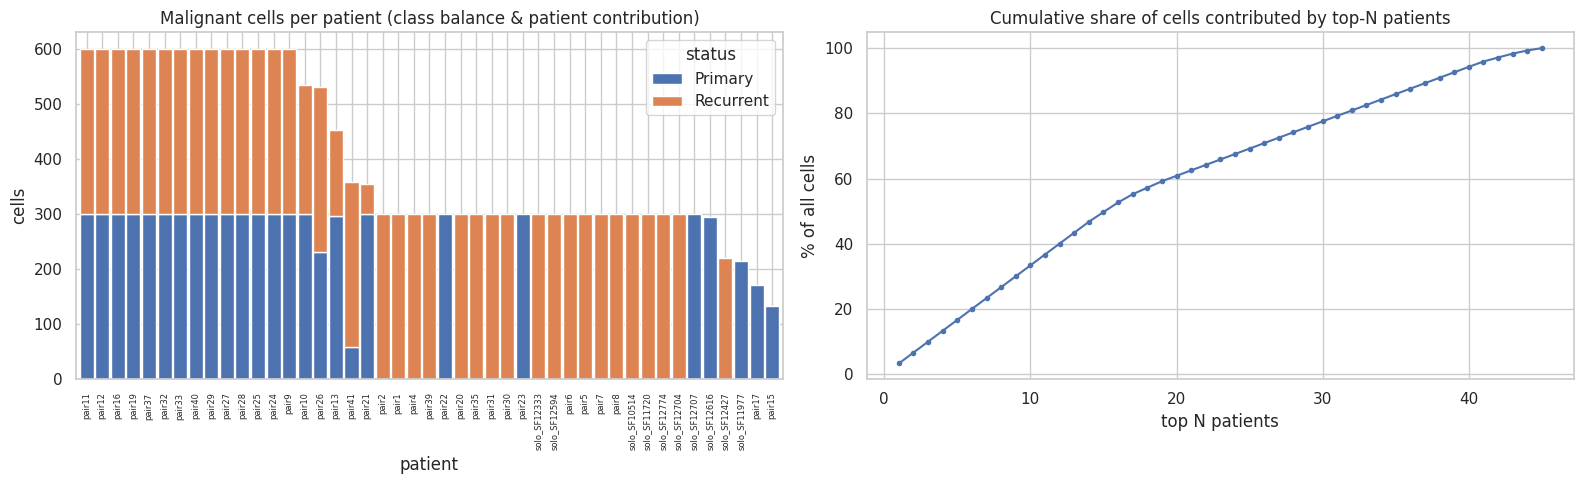

top-5 patients contribute 16.7% of all cells


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ct_sorted = ct.assign(total=ct.sum(1)).sort_values("total", ascending=False).drop(columns="total")
ct_sorted.plot.bar(stacked=True, ax=ax[0], color={"Primary": "#4C72B0", "Recurrent": "#DD8452"}, width=0.9)
ax[0].set_title("Malignant cells per patient (class balance & patient contribution)"); ax[0].set_xlabel("patient"); ax[0].set_ylabel("cells")
ax[0].tick_params(axis="x", labelsize=6)
share = (ct.sum(1).sort_values(ascending=False).cumsum() / ct.values.sum()).values
ax[1].plot(np.arange(1, len(share) + 1), share * 100, marker="o", ms=3)
ax[1].set_title("Cumulative share of cells contributed by top-N patients"); ax[1].set_xlabel("top N patients"); ax[1].set_ylabel("% of all cells")
plt.tight_layout(); savefig("eda_01_cells_per_patient.png")
print(f"top-5 patients contribute {share[min(4, len(share)-1)]*100:.1f}% of all cells")

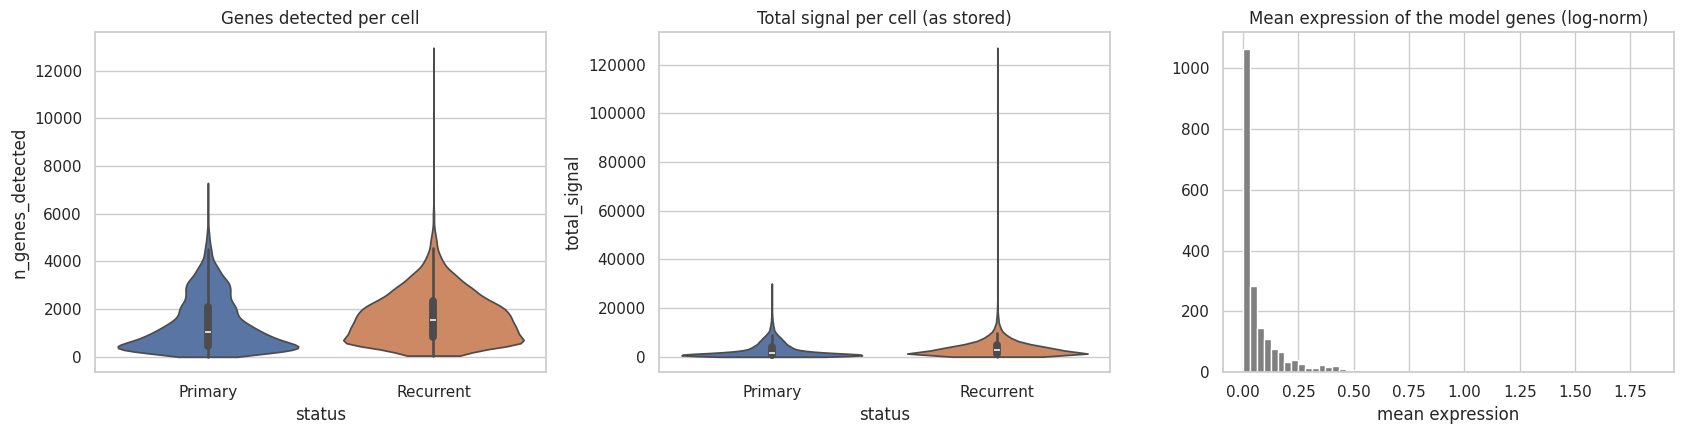

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
pal = {"Primary": "#4C72B0", "Recurrent": "#DD8452"}
sns.violinplot(data=o, x="status", y="n_genes_detected", palette=pal, ax=ax[0], cut=0); ax[0].set_title("Genes detected per cell")
sns.violinplot(data=o, x="status", y="total_signal", palette=pal, ax=ax[1], cut=0); ax[1].set_title("Total signal per cell (as stored)")
mean_expr = Xmat.mean(0); ax[2].hist(mean_expr, bins=60, color="gray"); ax[2].set_title("Mean expression of the model genes (log-norm)")
ax[2].set_xlabel("mean expression"); plt.tight_layout(); savefig("eda_02_qc_distributions.png")

In [16]:
import numba
numba.set_num_threads(min(2, numba.config.NUMBA_NUM_THREADS))
sc.settings.n_jobs = 2

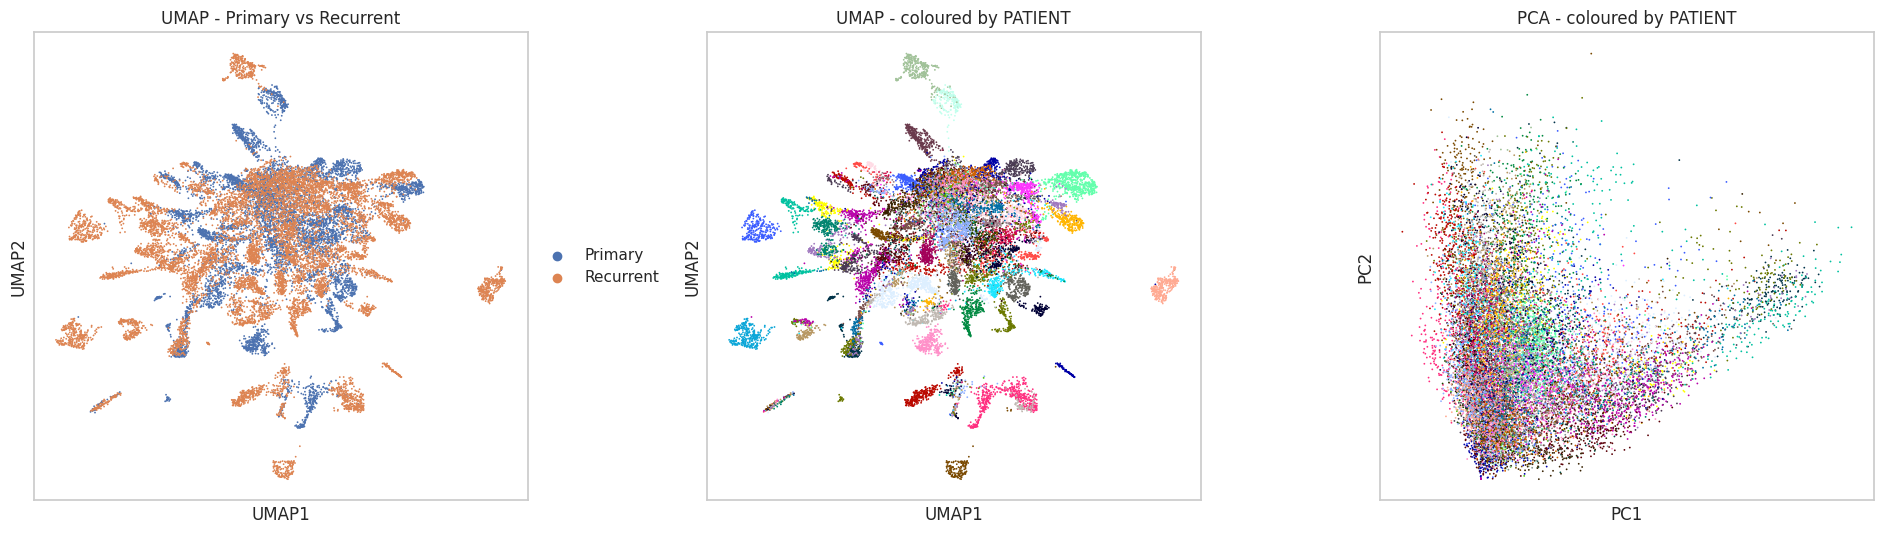

In [17]:
# ---------------- PCA / UMAP (visualisation only; labels are never used) ----------------
viz = adata_hvg.copy()
if viz.n_obs > 30000: viz = viz[np.random.RandomState(SEED).choice(viz.n_obs, 30000, replace=False)].copy()
sc.pp.scale(viz, max_value=10); sc.tl.pca(viz, n_comps=50, random_state=SEED)
sc.pp.neighbors(viz, n_neighbors=15, n_pcs=30, random_state=SEED); sc.tl.umap(viz, random_state=SEED)
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
sc.pl.umap(viz, color="status", ax=ax[0], show=False, title="UMAP - Primary vs Recurrent", palette=pal)
sc.pl.umap(viz, color="patient", ax=ax[1], show=False, title="UMAP - coloured by PATIENT", legend_loc=None)
sc.pl.pca(viz, color="patient", ax=ax[2], show=False, title="PCA - coloured by PATIENT", legend_loc=None)
plt.tight_layout(); savefig("eda_03_umap_pca.png")

In [18]:
# ---------------- how strong is patient structure vs class structure? (the heart of the leakage argument) ----------------
Z = viz.obsm["X_pca"][:, :30]; vp = viz.obs["patient"].values; vs = viz.obs["status"].values
sub = np.random.RandomState(SEED).choice(len(Z), min(8000, len(Z)), replace=False)
nn = NearestNeighbors(n_neighbors=16).fit(Z); _, idx = nn.kneighbors(Z[sub]); idx = idx[:, 1:]
same_pat = (vp[idx] == vp[sub][:, None]).mean(); same_sta = (vs[idx] == vs[sub][:, None]).mean()
chance_pat = float(((pd.Series(vp).value_counts(normalize=True)) ** 2).sum()); chance_sta = float(((pd.Series(vs).value_counts(normalize=True)) ** 2).sum())
sil_pat = silhouette_score(Z[sub], vp[sub]); sil_sta = silhouette_score(Z[sub], vs[sub])
res = pd.DataFrame({"neighbours sharing label": [same_pat, same_sta], "chance level": [chance_pat, chance_sta],
                    "enrichment (x chance)": [same_pat / chance_pat, same_sta / chance_sta], "silhouette": [sil_pat, sil_sta]},
                   index=["same PATIENT", "same STATUS (Primary/Recurrent)"])
display(res.round(3)); res.round(4).to_csv(OUT_DIR / "eda_patient_structure.csv")
print("If 'same PATIENT' enrichment >> 'same STATUS' enrichment, a random cell split can reach high accuracy just by recognising patients.")

,neighbours sharing label,chance level,enrichment (x chance),silhouette
same PATIENT,0.704,0.025,27.765,-0.032
same STATUS (Primary/Recurrent),0.846,0.522,1.620,-0.002


If 'same PATIENT' enrichment >> 'same STATUS' enrichment, a random cell split can reach high accuracy just by recognising patients.


## 5. Experiments

**Experiment A – cell-level CV:** `StratifiedKFold`; nuclei from one specimen/patient can appear in both training and test folds. This is an intentionally optimistic, identity-sharing benchmark.

**Experiment B – patient-level CV:** `StratifiedGroupKFold` with the integer-encoded `groups` derived from `adata_hvg.obs["patient"]`. Every outer fold must assert zero patient overlap.

**Preprocessing caveat:** the original experiments scale inside the model pipeline, but use globally selected HVGs. They are not fully leakage-free. Treat them as the global-HVG comparison. The added fold-internal analysis performs HVG selection and scaling within each training fold; grouped inner CV is used whenever tuning is enabled.


In [19]:
def make_model(name):
    if name == "LogReg":
        return Pipeline([("scaler", StandardScaler()),
                         ("clf", LogisticRegression(penalty="l2", C=0.05, solver="lbfgs", max_iter=500, class_weight="balanced"))])
    if name == "ElasticNet":
        return Pipeline([("scaler", StandardScaler()),
                         ("clf", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=0.05, max_iter=300,
                                                    tol=1e-3, class_weight="balanced", random_state=SEED))])
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3, class_weight="balanced_subsample",
                                      n_jobs=-1, random_state=SEED)
    if name == "XGBoost":
        return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
                             tree_method="hist", n_jobs=-1, eval_metric="logloss", random_state=SEED, verbosity=0)
    raise ValueError(name)

PARAM_GRIDS = {   # used only if TUNE=True (training data of each outer fold only)
    "LogReg":       [{"clf__C": c} for c in (0.005, 0.05, 0.5)],
    "ElasticNet":   [{"clf__C": c, "clf__l1_ratio": l} for c in (0.02, 0.2) for l in (0.3, 0.7)],
    "RandomForest": [{"min_samples_leaf": m, "max_features": f} for m in (3, 10) for f in ("sqrt", 0.1)],
    "XGBoost":      [{"max_depth": d, "learning_rate": lr} for d in (3, 5) for lr in (0.05, 0.1)],
}

def metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int); two = len(np.unique(y_true)) == 2
    return {"ROC_AUC": roc_auc_score(y_true, prob) if two else np.nan,
            "PR_AUC": average_precision_score(y_true, prob) if two else np.nan,
            "F1": f1_score(y_true, pred, zero_division=0), "Balanced_Acc": balanced_accuracy_score(y_true, pred),
            "Sensitivity": recall_score(y_true, pred, pos_label=1, zero_division=0),
            "Specificity": recall_score(y_true, pred, pos_label=0, zero_division=0),
            "Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0)}

def importance_vector(model):
    est = model.named_steps["clf"] if hasattr(model, "named_steps") else model
    return np.abs(est.coef_).ravel() if hasattr(est, "coef_") else np.asarray(est.feature_importances_, dtype=float)

def tune(name, base, Xtr, ytr, gtr, design, seed):
    # inner CV mirrors the outer design: cell-level inner for A, patient-grouped inner for B
    try:
        inner = (StratifiedKFold(3, shuffle=True, random_state=seed).split(Xtr, ytr) if design == "cell"
                 else StratifiedGroupKFold(3, shuffle=True, random_state=seed).split(Xtr, ytr, gtr))
        inner = list(inner); best, best_s = {}, -1
        for params in PARAM_GRIDS[name]:
            sc_ = []
            for a, b in inner:
                m = clone(base).set_params(**params).fit(Xtr[a], ytr[a]); sc_.append(roc_auc_score(ytr[b], m.predict_proba(Xtr[b])[:, 1]))
            if np.mean(sc_) > best_s: best, best_s = params, np.mean(sc_)
        return best
    except Exception as e:
        print("tuning skipped:", e); return {}

def run_cv(design):
    rows, oof, imps = [], [], defaultdict(list)
    total = N_REPEATS * N_SPLITS * len(MODELS_TO_RUN); pbar = tqdm(total=total, desc=f"Experiment {'A (cell)' if design=='cell' else 'B (patient)'}")
    for rep in range(N_REPEATS):
        seed = SEED + rep
        spl = (StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed).split(Xmat, y) if design == "cell"
               else StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed).split(Xmat, y, groups))
        for fold, (tr, te) in enumerate(spl):
            shared = len(set(groups[tr]) & set(groups[te]))
            if design == "patient": assert shared == 0, "LEAKAGE: a patient is in both train and test!"
            for name in MODELS_TO_RUN:
                m = make_model(name)
                if name == "XGBoost": m.set_params(scale_pos_weight=(y[tr] == 0).sum() / max(1, (y[tr] == 1).sum()))
                if TUNE: m.set_params(**tune(name, m, Xmat[tr], y[tr], groups[tr], design, seed))
                m.fit(Xmat[tr], y[tr]); p = m.predict_proba(Xmat[te])[:, 1]
                rows.append({"design": design, "repeat": rep, "fold": fold, "model": name, "n_train": len(tr), "n_test": len(te),
                             "test_patients": len(np.unique(groups[te])), "patients_shared_train_test": shared, **metrics(y[te], p)})
                imps[name].append(importance_vector(m))
                oof.append(pd.DataFrame({"idx": te, "prob": p, "y": y[te], "model": name, "repeat": rep, "fold": fold, "design": design}))
                pbar.update(1)
    pbar.close()
    return pd.DataFrame(rows), pd.concat(oof, ignore_index=True), imps

In [20]:
import pickle, hashlib
CACHE_DIR = OUT_DIR / "cache"; CACHE_DIR.mkdir(parents=True, exist_ok=True)
FORCE_RERUN = False        # set True to ignore the cache and recompute

def _cv_signature():
    cfg = dict(N_REPEATS=N_REPEATS, N_SPLITS=N_SPLITS, MODELS=list(MODELS_TO_RUN), TUNE=bool(TUNE), SEED=SEED,
               shape=list(Xmat.shape))
    h = hashlib.md5(json.dumps(cfg, sort_keys=True).encode())
    h.update(np.asarray(y).tobytes()); h.update(",".join(map(str, groups)).encode())
    h.update(np.ascontiguousarray(Xmat[:50, :50]).tobytes())          # cheap fingerprint of the data
    return h.hexdigest()[:12]

def run_cv_cached(design):
    f = CACHE_DIR / f"cv_{design}_{_cv_signature()}.pkl"
    if f.exists() and not FORCE_RERUN:
        with open(f, "rb") as fh: out = pickle.load(fh)
        print(f"loaded cached Experiment ({design}) from {f.name}"); return out
    res, oof, imps = run_cv(design)
    out = (res, oof, dict(imps))
    with open(f, "wb") as fh: pickle.dump(out, fh)
    print(f"saved to {f}"); return out

res_A, oof_A, imp_A = run_cv_cached("cell")
print("Experiment A: patients shared between train/test folds (mean per fold):", res_A.patients_shared_train_test.mean().round(1))

loaded cached Experiment (cell) from cv_cell_7707239b63d3.pkl
Experiment A: patients shared between train/test folds (mean per fold): 45.0


In [21]:
res_B, oof_B, imp_B = run_cv_cached("patient")
print("Experiment B: patients shared between train/test folds (must be 0):", int(res_B.patients_shared_train_test.sum()))
results = pd.concat([res_A, res_B], ignore_index=True); results.to_csv(OUT_DIR / "fold_level_results.csv", index=False)
IMP = {("cell", m): np.vstack(v) for m, v in imp_A.items()} | {("patient", m): np.vstack(v) for m, v in imp_B.items()}
OOF = {"cell": oof_A, "patient": oof_B}

loaded cached Experiment (patient) from cv_patient_7707239b63d3.pkl
Experiment B: patients shared between train/test folds (must be 0): 0


## 6. Results: cell-level vs patient-level validation

In [22]:
METRICS = ["ROC_AUC", "PR_AUC", "F1", "Balanced_Acc", "Sensitivity", "Specificity", "Accuracy", "Precision"]
agg = results.groupby(["model", "design"])[METRICS].agg(["mean", "std"])
mean_tbl = results.groupby(["model", "design"])[METRICS].mean().unstack("design")
summary_rows = []
for m in MODELS_TO_RUN:
    r = {"model": m}
    for k in METRICS:
        a, b = mean_tbl.loc[m, (k, "cell")], mean_tbl.loc[m, (k, "patient")]
        r[f"{k}_cell"], r[f"{k}_patient"], r[f"{k}_gap(A-B)"] = a, b, a - b
    summary_rows.append(r)
summary = pd.DataFrame(summary_rows).set_index("model")
display(summary[[c for c in summary.columns if c.startswith(("ROC_AUC", "PR_AUC", "F1", "Balanced_Acc"))]].round(3))
baseline_rows = []
for model_name in MODELS_TO_RUN:
    for design_name in ("cell", "patient"):
        d = results[(results.model == model_name) & (results.design == design_name)]
        baseline_rows.append({"model": model_name, "design": design_name,
                              "mean_test_prevalence": float(y.mean()),
                              "all_positive_F1_baseline": float(2 * y.mean() / (1 + y.mean()))})
baseline_table = pd.DataFrame(baseline_rows)
print("Always-positive comparator (same overall prevalence; compare directly with F1, not ROC-AUC):")
display(baseline_table)
baseline_table.to_csv(OUT_DIR / "all_positive_F1_baseline.csv", index=False)
summary.round(4).to_csv(OUT_DIR / "summary_metrics_and_gap.csv"); agg.round(4).to_csv(OUT_DIR / "mean_std_by_model_design.csv")
print(f"Reference: random-classifier PR_AUC = class prevalence = {y.mean():.3f}; ROC_AUC = 0.5")

,ROC_AUC_cell,ROC_AUC_patient,ROC_AUC_gap(A-B),PR_AUC_cell,PR_AUC_patient,PR_AUC_gap(A-B),F1_cell,F1_patient,F1_gap(A-B),Balanced_Acc_cell,Balanced_Acc_patient,Balanced_Acc_gap(A-B)
model,,,,,,,,,,,,
LogReg,0.881,0.551,0.330,0.917,0.673,0.244,0.833,0.604,0.229,0.801,0.526,0.275
ElasticNet,0.892,0.552,0.341,0.926,0.673,0.252,0.841,0.604,0.236,0.812,0.529,0.283
RandomForest,0.952,0.579,0.373,0.969,0.677,0.292,0.903,0.684,0.218,0.866,0.560,0.306
XGBoost,0.956,0.573,0.382,0.971,0.679,0.291,0.907,0.634,0.273,0.887,0.545,0.341


Always-positive comparator (same overall prevalence; compare directly with F1, not ROC-AUC):


,model,design,mean_test_prevalence,all_positive_F1_baseline
0,LogReg,cell,0.604843,0.753772
1,LogReg,patient,0.604843,0.753772
2,ElasticNet,cell,0.604843,0.753772
3,ElasticNet,patient,0.604843,0.753772
4,RandomForest,cell,0.604843,0.753772
5,RandomForest,patient,0.604843,0.753772
6,XGBoost,cell,0.604843,0.753772
7,XGBoost,patient,0.604843,0.753772


Reference: random-classifier PR_AUC = class prevalence = 0.605; ROC_AUC = 0.5


### Permutation tests: patient-held-out performance vs a structured null

Permutation tests are exploratory inferential controls. The current specimen-label permutation preserves cell blocks but does not create independent patient-level replication. Report raw and Holm-adjusted p-values together; **do not call any raw p-value significant if it does not survive the pre-declared Holm family correction**. The pre-declared primary test should be the patient-held-out Logistic Regression ROC-AUC permutation test; the remaining tests are secondary.


In [23]:
# ---------------- label-permutation test: light + crash-safe (checkpoint after EVERY permutation) ----------------
import gc, psutil
for _n in ["adata", "adata_hvg", "parts"]:
    if _n in globals(): del globals()[_n]
gc.collect()
def ram(): return f"{psutil.virtual_memory().used/1e9:.1f}/{psutil.virtual_memory().total/1e9:.1f} GB"
print("RAM at start:", ram())

PERM_CELLS_PER_SAMPLE = 100      # use a fixed random 100 cells per specimen for this test only (3x faster, far less memory)
_rs = np.random.RandomState(0)
_sub = np.sort(np.concatenate([_rs.choice(np.where(sample_ids == s)[0], min(PERM_CELLS_PER_SAMPLE, (sample_ids == s).sum()), replace=False)
                               for s in np.unique(sample_ids)]))
Xp, yp, gp, sp_ids = Xmat[_sub], y[_sub], groups[_sub], sample_ids[_sub]
print(f"permutation-test data: {Xp.shape[0]:,} cells x {Xp.shape[1]} genes, {len(np.unique(sp_ids))} specimens")

def patient_cv_auc(yy, model_name, seed, n_est=None):
    aucs = []
    for tr, te in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed).split(Xp, yy, gp):
        if len(np.unique(yy[te])) < 2: continue
        m = make_model(model_name)
        if n_est: m.set_params(n_estimators=n_est)
        m.fit(Xp[tr], yy[tr]); aucs.append(roc_auc_score(yy[te], m.predict_proba(Xp[te])[:, 1]))
    return np.mean(aucs)

spec_lab = pd.Series(yp).groupby(sp_ids).first()      # one label per specimen

def permutation_test(model_name, n_perm, n_est=None):
    f = CACHE_DIR / f"perm_{model_name}_{n_est}_cps{PERM_CELLS_PER_SAMPLE}_{_cv_signature()}.pkl"
    state = {"obs": None, "null": []}
    if f.exists() and not FORCE_RERUN:
        with open(f, "rb") as fh: state = pickle.load(fh)
        print(f"{model_name}: resuming from checkpoint ({len(state['null'])} permutations done)")
    if state["obs"] is None:
        state["obs"] = np.mean([patient_cv_auc(yp, model_name, SEED + r, n_est) for r in range(N_REPEATS)])
        with open(f, "wb") as fh: pickle.dump(state, fh)
    rng = np.random.RandomState(0)
    perms = [pd.Series(rng.permutation(spec_lab.values), index=spec_lab.index) for _ in range(n_perm)]
    bar = tqdm(range(len(state["null"]), n_perm), desc=f"perm {model_name}", initial=len(state["null"]), total=n_perm)
    for p in bar:
        state["null"].append(patient_cv_auc(perms[p].loc[sp_ids].values, model_name, SEED + p, n_est))
        with open(f, "wb") as fh: pickle.dump(state, fh)          # save after every permutation
        gc.collect(); bar.set_postfix(RAM=ram())
    null = np.array(state["null"][:n_perm]); obs_auc = state["obs"]; pval = (1 + (null >= obs_auc).sum()) / (1 + len(null))
    print(f"{model_name}: observed patient-level AUC = {obs_auc:.3f} | null mean = {null.mean():.3f} "
          f"(95th pct {np.percentile(null, 95):.3f}) | p = {pval:.3f}  (n_perm = {len(null)})")
    return obs_auc, null, pval

perm_LR = permutation_test("LogReg", n_perm=200)      # was 30

RAM at start: 3.9/13.6 GB
permutation-test data: 6,314 cells x 2000 genes, 64 specimens
LogReg: resuming from checkpoint (200 permutations done)


perm LogReg: 100%|##########| 200/200 [00:00<?, ?it/s]

LogReg: observed patient-level AUC = 0.541 | null mean = 0.499 (95th pct 0.569) | p = 0.164  (n_perm = 200)


In [24]:
perm_RF = permutation_test("RandomForest", n_perm=100, n_est=60)     # was 19; min possible p = 0.01
prev = float(np.mean(y)); print(f"F1 of 'always predict {POSITIVE_LABEL}' = {2*prev/(1+prev):.3f}  (compare with patient-level F1; ROC-AUC / balanced accuracy are the fairer metrics)")

RandomForest: resuming from checkpoint (100 permutations done)


perm RandomForest: 100%|##########| 100/100 [00:00<?, ?it/s]

RandomForest: observed patient-level AUC = 0.567 | null mean = 0.497 (95th pct 0.615) | p = 0.129  (n_perm = 100)
F1 of 'always predict Recurrent' = 0.754  (compare with patient-level F1; ROC-AUC / balanced accuracy are the fairer metrics)


In [25]:
# ---------------- save the permutation-test results (and the full-data patient-level numbers) to CSV ----------------
rows = []
for name, (obs, null, p) in {"LogReg": perm_LR, "RandomForest": perm_RF}.items():
    full = results[(results.design == "patient") & (results.model == name)].ROC_AUC
    rows.append(dict(model=name, observed_AUC_subsample=obs, null_mean=null.mean(), null_sd=null.std(), null_95th=np.percentile(null, 95),
                     n_perm=len(null), p_value=p, full_data_patient_AUC_mean=full.mean(), full_data_patient_AUC_sd=full.std(),
                     cells_per_specimen_in_test=PERM_CELLS_PER_SAMPLE))
perm_df = pd.DataFrame(rows); display(perm_df.round(3))
perm_df.to_csv(OUT_DIR / "permutation_test_summary.csv", index=False)
pd.DataFrame({"LogReg_null_AUC": pd.Series(perm_LR[1]), "RandomForest_null_AUC": pd.Series(perm_RF[1])}).to_csv(OUT_DIR / "permutation_null_distributions.csv", index=False)
print("saved to", OUT_DIR)

,model,observed_AUC_subsample,null_mean,null_sd,null_95th,n_perm,p_value,full_data_patient_AUC_mean,full_data_patient_AUC_sd,cells_per_specimen_in_test
0,LogReg,0.541,0.499,0.042,0.569,200,0.164,0.551,0.075,100
1,RandomForest,0.567,0.497,0.064,0.615,100,0.129,0.579,0.091,100


saved to /content/drive/MyDrive/DSTT_GBM/GBM_leakage_project_outputs


### Paired analysis (patients with BOTH a Primary and a Recurrent specimen)
Each patient is its own control; the null swaps Primary/Recurrent labels *within* each patient.

In [26]:
# ---------------- PAIRED analysis: only patients with BOTH a Primary and a Recurrent specimen ----------------
# Each patient is its own control. Patient-held-out CV on these patients + a paired permutation test
# (null: randomly swap the Primary/Recurrent labels WITHIN each patient, which keeps the pairing structure).
import gc
POS = 1                                                    # y == 1 is the positive class (Recurrent)
PAIRED_CELLS_PER_SAMPLE = 100
pat_nstat = pd.Series(y).groupby(groups).nunique()
paired_patients = pat_nstat.index[pat_nstat.values == 2]
_rs = np.random.RandomState(0); keep = []
for s in np.unique(sample_ids[np.isin(groups, paired_patients)]):
    idx = np.where(sample_ids == s)[0]; keep.append(_rs.choice(idx, min(PAIRED_CELLS_PER_SAMPLE, len(idx)), replace=False))
keep = np.sort(np.concatenate(keep))
Xq, yq, gq, sq = Xmat[keep], y[keep], groups[keep], sample_ids[keep]
print(f"paired patients: {len(paired_patients)} | specimens: {len(np.unique(sq))} | cells: {len(keep):,} "
      f"(Primary {(yq==0).sum():,} / Recurrent {(yq==1).sum():,})")

def paired_cv(yy, model_name, seed, n_est=None):
    aucs, bals = [], []
    for tr, te in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed).split(Xq, yy, gq):
        if len(np.unique(yy[te])) < 2 or len(np.unique(yy[tr])) < 2: continue
        m = make_model(model_name)
        if n_est: m.set_params(n_estimators=n_est)
        m.fit(Xq[tr], yy[tr]); pr = m.predict_proba(Xq[te])[:, 1]
        aucs.append(roc_auc_score(yy[te], pr)); bals.append(balanced_accuracy_score(yy[te], (pr >= 0.5).astype(int)))
    return np.mean(aucs), np.mean(bals)

def flip_within_patient(rng):
    flip = {p: rng.rand() < 0.5 for p in paired_patients}
    return np.array([1 - v if flip[g] else v for v, g in zip(yq, gq)])

def paired_test(model_name, n_perm, n_est=None):
    f = CACHE_DIR / f"paired_{model_name}_{n_est}_c{PAIRED_CELLS_PER_SAMPLE}_{_cv_signature()}.pkl"
    st = {"obs": None, "null": []}
    if f.exists() and not FORCE_RERUN:
        with open(f, "rb") as fh: st = pickle.load(fh); print(f"{model_name}: resuming ({len(st['null'])} permutations done)")
    if st["obs"] is None:
        r = [paired_cv(yq, model_name, SEED + k, n_est) for k in range(N_REPEATS)]
        st["obs"] = (np.mean([a for a, _ in r]), np.mean([b for _, b in r]))
        with open(f, "wb") as fh: pickle.dump(st, fh)
    rng = np.random.RandomState(1); flips = [flip_within_patient(rng) for _ in range(n_perm)]      # same flips every run
    for p in tqdm(range(len(st["null"]), n_perm), desc=f"paired {model_name}", initial=len(st["null"]), total=n_perm):
        st["null"].append(paired_cv(flips[p], model_name, SEED + p, n_est)[0])
        with open(f, "wb") as fh: pickle.dump(st, fh)
    null = np.array(st["null"][:n_perm]); obs, bal = st["obs"]; pval = (1 + (null >= obs).sum()) / (1 + len(null))
    print(f"{model_name}: PAIRED patient-held-out AUC = {obs:.3f} | balanced acc = {bal:.3f} | null mean = {null.mean():.3f} "
          f"(95th pct {np.percentile(null, 95):.3f}) | p = {pval:.3f} (n_perm = {len(null)})")
    return dict(model=model_name, n_patients=len(paired_patients), n_specimens=len(np.unique(sq)), n_cells=len(keep),
                observed_AUC=obs, observed_balanced_acc=bal, null_mean=null.mean(), null_sd=null.std(),
                null_95th=np.percentile(null, 95), n_perm=len(null), p_value=pval)

paired_rows = [paired_test("LogReg", n_perm=200), paired_test("RandomForest", n_perm=100, n_est=60)]   # were 50 and 19
paired_df = pd.DataFrame(paired_rows); display(paired_df.round(3))
paired_df.to_csv(OUT_DIR / "paired_patients_analysis.csv", index=False)
print("saved:", OUT_DIR / "paired_patients_analysis.csv")

paired patients: 19 | specimens: 38 | cells: 3,714 (Primary 1,859 / Recurrent 1,855)
LogReg: resuming (200 permutations done)


paired LogReg: 100%|##########| 200/200 [00:00<?, ?it/s]

LogReg: PAIRED patient-held-out AUC = 0.583 | balanced acc = 0.552 | null mean = 0.497 (95th pct 0.572) | p = 0.040 (n_perm = 200)
RandomForest: resuming (100 permutations done)


paired RandomForest: 100%|##########| 100/100 [00:00<?, ?it/s]

RandomForest: PAIRED patient-held-out AUC = 0.584 | balanced acc = 0.571 | null mean = 0.493 (95th pct 0.584) | p = 0.059 (n_perm = 100)


,model,n_patients,n_specimens,n_cells,observed_AUC,observed_balanced_acc,null_mean,null_sd,null_95th,n_perm,p_value
0,LogReg,19,38,3714,0.583,0.552,0.497,0.046,0.572,200,0.040
1,RandomForest,19,38,3714,0.584,0.571,0.493,0.058,0.584,100,0.059


saved: /content/drive/MyDrive/DSTT_GBM/GBM_leakage_project_outputs/paired_patients_analysis.csv


## Additional analyses for the paper
1. **Confounding audit** - is status confounded with batch? how much variance is patient vs status?
2. **Pseudobulk baseline** - one profile per specimen + paired differential expression
3. **Leakage ladder** - how much does each validation mistake inflate AUC?
4. **Bootstrap CIs** over patients and a test of the cell-vs-patient gap
5. **Simulation** - label-free data with patient effects (why cell-level CV leaks)

Run the helper cell first. Every slow step is cached to Drive.

In [27]:
# ===== T0: shared helpers for the extra analyses (run this once, before the cells below) =====
import gc, pickle, warnings
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore", category=FutureWarning)

def subsample_idx(n_per_sample, seed=0):
    """fixed random subset: up to n_per_sample cells from every specimen"""
    rs = np.random.RandomState(seed); out = []
    for s in np.unique(sample_ids):
        idx = np.where(sample_ids == s)[0]; out.append(rs.choice(idx, min(n_per_sample, len(idx)), replace=False))
    return np.sort(np.concatenate(out))

def cached(name, fn):
    """compute once, then load from Drive (cache is tied to the data/settings via _cv_signature)"""
    f = CACHE_DIR / f"{name}_{_cv_signature()}.pkl"
    if f.exists() and not FORCE_RERUN:
        with open(f, "rb") as fh: print(f"  loaded cache: {f.name}"); return pickle.load(fh)
    out = fn()
    with open(f, "wb") as fh: pickle.dump(out, fh)
    return out
print("helpers ready")

helpers ready


### 1. Confounding / batch audit

The GEO metadata audit is limited by the fields actually present. If no sequencing lane/library/batch field is available, the analysis cannot rule out technical confounding. A metadata block or submission date is not automatically a sequencing batch.


batch-like candidate variables found: ['gsm_block', 'submission_date', 'char_diagnosis', 'char_gender']

[gsm_block] vs status  (association p = 0.51;  small p = batch and status are confounded)


status,Primary,Recurrent
gsm_block,,
GSM531,26,36
GSM619,0,2



[submission_date] vs status  (association p = 0.51;  small p = batch and status are confounded)


status,Primary,Recurrent
submission_date,,
May 17 2021,26,36
May 26 2022,0,2



[char_diagnosis] vs status  (association p = 0.51;  small p = batch and status are confounded)


status,Primary,Recurrent
char_diagnosis,,
Brain tumor,0,2
GBM,26,36



[char_gender] vs status  (association p = 0.418;  small p = batch and status are confounded)


status,Primary,Recurrent
char_gender,,
Female,14,20
Male,11,16
None,1,0
male,0,2


,target,patient-held-out AUC (LogReg)
0,status (Primary/Recurrent),0.552


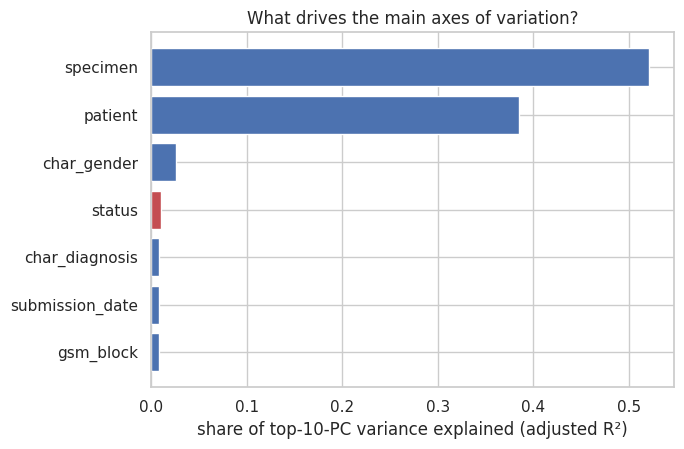

CAVEAT: 'gsm_block' has one category covering 97% of specimens -> it cannot test batch confounding.
CAVEAT: 'submission_date' has one category covering 97% of specimens -> it cannot test batch confounding.
CAVEAT: 'char_diagnosis' has one category covering 97% of specimens -> it cannot test batch confounding.
Note: no sequencing-batch/lane variable is available in the GEO metadata, so batch confounding with status cannot be excluded.


In [28]:
# ===== T1: batch / confounding audit (is status confounded with batch? how much variance is patient vs status vs batch?) =====
spec = pd.DataFrame({"sample": sample_ids, "patient": groups, "status": np.where(y == 1, "Recurrent", "Primary")}).drop_duplicates("sample").set_index("sample")
if "gse" in globals(): gse_ = gse                                          # already loaded by the loader cell
else:
    import GEOparse; gse_ = GEOparse.get_GEO("GSE174554", destdir="/content/geo", silent=True)
geo_by_sf = GEO.reset_index().drop_duplicates("sf").set_index("sf")
rows = []
for s in spec.index:
    if s not in geo_by_sf.index: rows.append({}); continue
    gsm_id = geo_by_sf.loc[s, "gsm"]; md = gse_.gsms[gsm_id].metadata
    r = {"gsm_block": gsm_id[:6], "submission_date": md.get("submission_date", [None])[0], "instrument": md.get("instrument_model", [None])[0]}
    for kv in md.get("characteristics_ch1", []):
        if ":" in kv: k, v = kv.split(":", 1); r["char_" + k.strip().lower()] = v.strip()
    rows.append(r)
spec = pd.concat([spec, pd.DataFrame(rows, index=spec.index)], axis=1)
skip = {"patient", "status", "char_progression", "char_pair#"}
cands = [c for c in spec.columns if c not in skip and 2 <= spec[c].nunique() <= 8]
print("batch-like candidate variables found:", cands)

# ---- 1. is status associated with each candidate? ----
for c in cands:
    ct = pd.crosstab(spec[c].fillna("NA"), spec["status"])
    p = stats.fisher_exact(ct.values)[1] if ct.shape == (2, 2) else stats.chi2_contingency(ct.values)[1]
    print(f"\n[{c}] vs status  (association p = {p:.3g};  small p = batch and status are confounded)"); display(ct)

# ---- 2. can expression predict the batch variable on held-out patients? (compare with status) ----
idx = subsample_idx(100, seed=2); Xs, gs, ss, ys = Xmat[idx], groups[idx], sample_ids[idx], y[idx]
def held_out_auc(target):
    aucs = []
    for tr, te in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(Xs, target, gs):
        if len(np.unique(target[te])) < 2 or len(np.unique(target[tr])) < 2: continue
        m = make_model("LogReg").fit(Xs[tr], target[tr]); aucs.append(roc_auc_score(target[te], m.predict_proba(Xs[te])[:, 1]))
    return np.mean(aucs) if aucs else np.nan
pred_rows = [("status (Primary/Recurrent)", held_out_auc(ys))]
for c in cands:
    lab = spec[c].fillna("NA").reindex(ss).values; vals = pd.Series(lab).value_counts()
    if len(vals) != 2 or vals.min() < 300: continue                       # only 2-class variables with enough cells
    pred_rows.append((f"{c}", held_out_auc((lab == vals.index[1]).astype(int))))
pred_df = pd.DataFrame(pred_rows, columns=["target", "patient-held-out AUC (LogReg)"]); display(pred_df.round(3))

# ---- 3. how much variance in the top PCs is explained by patient / specimen / status / batch? ----
Z = PCA(10, random_state=SEED).fit(StandardScaler().fit_transform(Xs)); evr = Z.explained_variance_ratio_
Zs = Z.transform(StandardScaler().fit(Xs).transform(Xs))
def adj_r2(z, f):
    f = pd.factorize(f)[0]; n, k = len(z), f.max() + 1; cnt = np.bincount(f)
    ss_b = (cnt * (np.bincount(f, z) / cnt - z.mean()) ** 2).sum(); r2 = ss_b / ((z - z.mean()) ** 2).sum()
    return max(0.0, 1 - (1 - r2) * (n - 1) / (n - k))
factors = {"patient": gs, "specimen": ss, "status": ys}
for c in cands: factors[c] = spec[c].fillna("NA").reindex(ss).values
ve = pd.Series({k: float(np.sum([adj_r2(Zs[:, j], v) * evr[j] for j in range(10)]) / evr.sum()) for k, v in factors.items()}).sort_values()
ve.rename("share_of_top10_PC_variance (adjusted R2)").to_csv(OUT_DIR / "variance_explained_by_factor.csv")
plt.figure(figsize=(7, 0.45 * len(ve) + 1.5)); plt.barh(ve.index, ve.values, color=["#C44E52" if k == "status" else "#4C72B0" for k in ve.index])
plt.xlabel("share of top-10-PC variance explained (adjusted R²)"); plt.title("What drives the main axes of variation?"); plt.tight_layout()
savefig("confound_01_variance_explained.png")
spec.to_csv(OUT_DIR / "specimen_table_with_batch_candidates.csv"); pred_df.to_csv(OUT_DIR / "batch_predictability.csv", index=False)
# ---- caveat: is any batch variable informative enough to rule confounding in or out? ----
for c in cands:
    top_share = spec[c].fillna("NA").value_counts(normalize=True).iloc[0]
    if top_share > 0.9:
        print(f"CAVEAT: '{c}' has one category covering {top_share:.0%} of specimens -> it cannot test batch confounding.")
print("Note: no sequencing-batch/lane variable is available in the GEO metadata, so batch confounding with status cannot be excluded.")

In [29]:
# ===== label sanity check: our status / patient vs GEO's own characteristics =====
if "char_progression" in spec.columns:
    print(pd.crosstab(spec["char_progression"].fillna("NA"), spec["status"]))
if "char_pair#" in spec.columns:
    print("max #pair# values per patient (must be 1):", spec.groupby("patient")["char_pair#"].nunique().max())
    print("max #patients per pair# (must be 1):", spec.groupby("char_pair#")["patient"].nunique().max())
display(spec[["patient", "status"] + [c for c in spec.columns if c in ("char_progression", "char_pair#")]].sort_values("patient").head(20))

status            Primary  Recurrent
char_progression                    
Primary                26          0
Recurrent               0         38
max #pair# values per patient (must be 1): 1
max #patients per pair# (must be 1): 10


,patient,status,char_progression,char_pair#
sample,,,,
SF10099,0,Primary,Primary,#9
SF10441,0,Recurrent,Recurrent,#9
SF11248,1,Recurrent,Recurrent,#19
SF10432,1,Primary,Primary,#19
SF11082,2,Primary,Primary,#28
SF11488,2,Recurrent,Recurrent,#28
SF12460,3,Recurrent,Recurrent,#40
SF11344,3,Primary,Primary,#40
SF11587,4,Primary,Primary,#23


### 2. Pseudobulk baseline + paired differential expression

In [30]:
# ===== T2: pseudobulk baseline (one profile per specimen) + paired differential expression =====
PB_REPEATS = 3
spec_ids = np.unique(sample_ids)
PB = np.vstack([Xmat[sample_ids == s].mean(0) for s in spec_ids])              # mean log-normalised expression per specimen
yb = np.array([y[sample_ids == s][0] for s in spec_ids]); gb = np.array([groups[sample_ids == s][0] for s in spec_ids])
print(f"pseudobulk: {len(spec_ids)} specimens x {PB.shape[1]} genes | Recurrent = {yb.mean():.0%} | patients = {len(np.unique(gb))}")

def pb_auc(yy, model_name, seed0, n_est=None):
    aucs = []
    for r in range(PB_REPEATS):
        oof = np.full(len(yy), np.nan)
        for tr, te in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed0 + r).split(PB, yy, gb):
            m = make_model(model_name)
            if n_est: m.set_params(n_estimators=n_est, n_jobs=1)          # tiny data: one thread is faster
            m.fit(PB[tr], yy[tr]); oof[te] = m.predict_proba(PB[te])[:, 1]
        aucs.append(roc_auc_score(yy, oof))
    return float(np.mean(aucs))

def pb_test(model_name, n_perm, n_est=None):
    def run():
        obs = pb_auc(yb, model_name, SEED, n_est); rng = np.random.RandomState(0)
        null = np.array([pb_auc(rng.permutation(yb), model_name, SEED + 100 + p, n_est) for p in range(n_perm)])
        return obs, null
    obs, null = cached(f"pseudobulk_{model_name}_{n_perm}_{n_est}", run)
    p = (1 + (null >= obs).sum()) / (1 + len(null))
    print(f"pseudobulk {model_name}: patient-held-out AUC = {obs:.3f} | null mean = {null.mean():.3f} (95th pct {np.percentile(null, 95):.3f}) | p = {p:.3f} (n_perm = {len(null)})")
    return dict(model=model_name, n_specimens=len(yb), n_patients=len(np.unique(gb)), observed_AUC=obs, null_mean=null.mean(), null_95th=np.percentile(null, 95), n_perm=len(null), p_value=p)

pb_df = pd.DataFrame([pb_test("LogReg", 200), pb_test("RandomForest", 200, n_est=100)])   # RF was 50
pb_df.to_csv(OUT_DIR / "pseudobulk_baseline.csv", index=False)

# ---- paired differential expression: Recurrent - Primary within each patient (Wilcoxon signed-rank, BH-FDR) ----
nst = pd.Series(yb).groupby(gb).nunique(); pp = nst.index[nst.values == 2]
Pm = np.vstack([PB[(gb == p) & (yb == 0)].mean(0) for p in pp]); Rm = np.vstack([PB[(gb == p) & (yb == 1)].mean(0) for p in pp]); D = Rm - Pm
pv = np.array([stats.wilcoxon(D[:, j]).pvalue if np.any(D[:, j] != 0) else 1.0 for j in range(D.shape[1])])
o = np.argsort(pv); q = np.empty_like(pv); q[o] = np.minimum.accumulate((pv[o] * len(pv) / (np.arange(len(pv)) + 1))[::-1])[::-1]; q = np.minimum(q, 1)
de = pd.DataFrame({"gene": genes, "mean_diff_Rec_minus_Prim": D.mean(0), "p_value": pv, "q_BH": q}).sort_values("p_value")
de.to_csv(OUT_DIR / "pseudobulk_paired_wilcoxon.csv", index=False)
print(f"\npaired DE on {len(pp)} patients: genes with FDR < 0.05 = {(de.q_BH < 0.05).sum()} | FDR < 0.10 = {(de.q_BH < 0.10).sum()} | smallest possible p ≈ {2 / 2 ** len(pp):.1e}")
display(de.head(10).round(4))

pseudobulk: 64 specimens x 2000 genes | Recurrent = 59% | patients = 45
  loaded cache: pseudobulk_LogReg_200_None_7707239b63d3.pkl
pseudobulk LogReg: patient-held-out AUC = 0.562 | null mean = 0.477 (95th pct 0.629) | p = 0.159 (n_perm = 200)
  loaded cache: pseudobulk_RandomForest_200_100_7707239b63d3.pkl
pseudobulk RandomForest: patient-held-out AUC = 0.618 | null mean = 0.454 (95th pct 0.602) | p = 0.040 (n_perm = 200)

paired DE on 19 patients: genes with FDR < 0.05 = 0 | FDR < 0.10 = 0 | smallest possible p ≈ 3.8e-06


,gene,mean_diff_Rec_minus_Prim,p_value,q_BH
497,CPE,0.2189,0.0003,0.4754
1431,GABRG3,0.0305,0.0009,0.4754
538,SV2C,0.0665,0.0014,0.4754
481,ETNPPL,0.0831,0.0015,0.4754
1630,ABCC3,-0.2594,0.0017,0.4754
1605,MMP28,0.0307,0.0018,0.4754
1326,GJB6,0.0261,0.0019,0.4754
608,LY86-AS1,0.0113,0.0022,0.4754
1042,CACNA1B,0.0496,0.0024,0.4754
281,TUBA4A,0.0103,0.0026,0.4754


Cell-state composition baseline

In [31]:
# ===== baseline: GBM cell-state composition per specimen (scores from ALL filtered genes, not just HVGs) =====
import scanpy as sc
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
STATE_GENES = {   # approximate markers - swap in the published Neftel et al. 2019 signatures if you have them
    "MES": ["CHI3L1","CD44","VIM","ANXA1","ANXA2","S100A10","SERPINE1","LGALS3","VEGFA","ADM"],
    "AC":  ["GFAP","S100B","SLC1A3","AQP4","CLU","ALDOC","MLC1","ID3"],
    "OPC": ["PDGFRA","OLIG1","OLIG2","SOX10","CSPG4","APOD","GPR17"],
    "NPC": ["DCX","SOX11","STMN2","CD24","DLL3","ASCL1","MAP2"],
}
assert adata_full.n_obs == Xmat.shape[0], "adata_full not aligned with Xmat - re-run the QC/HVG cell"
av = set(adata_full.var_names)
for k, gl in STATE_GENES.items():
    print(k, "genes found in ALL filtered genes:", sum(g in av for g in gl), "/", len(gl))
    sc.tl.score_genes(adata_full, [g for g in gl if g in av], score_name=f"score_{k}", random_state=SEED)
S = adata_full.obs[[f"score_{k}" for k in STATE_GENES]].values
dom = S.argmax(1); spec_ids = np.unique(sample_ids)
F  = np.vstack([np.r_[S[sample_ids == s].mean(0), np.bincount(dom[sample_ids == s], minlength=4) / (sample_ids == s).sum()] for s in spec_ids])
yb = np.array([y[sample_ids == s][0] for s in spec_ids]); gb = np.array([groups[sample_ids == s][0] for s in spec_ids])

def comp_auc(yy, seed0, reps=5):
    out = []
    for r in range(reps):
        oof = np.full(len(yy), np.nan)
        for tr, te in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed0 + r).split(F, yy, gb):
            m = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000)).fit(F[tr], yy[tr]); oof[te] = m.predict_proba(F[te])[:, 1]
        out.append(roc_auc_score(yy, oof))
    return float(np.mean(out))
obs = comp_auc(yb, SEED); rng = np.random.RandomState(0)
null = np.array([comp_auc(rng.permutation(yb), SEED + 100 + p, reps=2) for p in range(200)])
p = (1 + (null >= obs).sum()) / (1 + len(null))
print(f"cell-state composition: patient-held-out AUC = {obs:.3f} | null mean = {null.mean():.3f} (95th {np.percentile(null, 95):.3f}) | p = {p:.3f}")
print("mean state scores  Primary vs Recurrent:"); display(pd.DataFrame(F[:, :4], columns=list(STATE_GENES)).groupby(yb).mean().rename(index={0: "Primary", 1: "Recurrent"}).round(3))
pd.DataFrame([dict(model="StateComposition_LogReg", observed_AUC=obs, null_mean=null.mean(), null_95th=np.percentile(null, 95), n_perm=200, p_value=p)]).to_csv(OUT_DIR / "cell_state_baseline.csv", index=False)

MES genes found in ALL filtered genes: 10 / 10
AC genes found in ALL filtered genes: 7 / 8
OPC genes found in ALL filtered genes: 7 / 7
NPC genes found in ALL filtered genes: 7 / 7
cell-state composition: patient-held-out AUC = 0.374 | null mean = 0.446 (95th 0.606) | p = 0.726
mean state scores  Primary vs Recurrent:


,MES,AC,OPC,NPC
Primary,0.016,0.147,-0.001,0.083
Recurrent,-0.009,0.188,-0.002,0.075


### 3. Leakage ladder (diagnostic, not a clean sequence of validation estimates)

The specimen-held-out rung leaves another specimen from the same patient in training. It is a **diagnostic of patient-level information sharing**, not a clean intermediate estimate of new-patient generalization. The ladder uses a different cell cap and feature-selection setup from the main experiments: `LADDER_CELLS=100` cells/specimen and `FS_K=200` selected genes, while the main analysis uses up to `MAX_CELLS_PER_SAMPLE=300` and 2,000 global HVGs. The Random Forest rung also uses 100 trees versus 300 in the main model. Thus the reported ladder values (e.g. LR 0.824 / RF 0.918) and main cell-level values (e.g. LR 0.881 / RF 0.953) are not a paired comparison; differences can reflect sample size, feature count, model configuration and fold composition. Report the ladder only as a qualitative diagnostic and do not compare these AUCs as if they came from identical data/splits.


  loaded cache: ladder_1_LogReg_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_1_RandomForest_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_2_LogReg_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_2_RandomForest_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_3_LogReg_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_3_RandomForest_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_4_LogReg_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_4_RandomForest_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_5_LogReg_100_200_2_7707239b63d3.pkl
  loaded cache: ladder_5_RandomForest_100_200_2_7707239b63d3.pkl


,rung,model,AUC_mean,AUC_sd,n_folds,inflation_vs_clean
0,"1. patient-held-out, genes selected inside fol...",LogReg,0.545,0.097,10,0.000
1,"1. patient-held-out, genes selected inside fol...",RandomForest,0.554,0.139,10,0.000
2,"2. patient-held-out, all 2000 genes (clean)",LogReg,0.542,0.069,10,0.000
3,"2. patient-held-out, all 2000 genes (clean)",RandomForest,0.558,0.134,10,0.000
4,"3. patient-held-out, genes selected on ALL dat...",LogReg,0.658,0.065,10,0.113
5,"3. patient-held-out, genes selected on ALL dat...",RandomForest,0.612,0.127,10,0.058
6,4. specimen-held-out (patient's other specimen...,LogReg,0.557,0.065,10,0.014
7,4. specimen-held-out (patient's other specimen...,RandomForest,0.597,0.070,10,0.040
8,5. random cell split (same specimen in train),LogReg,0.824,0.012,10,0.282
9,5. random cell split (same specimen in train),RandomForest,0.918,0.010,10,0.361


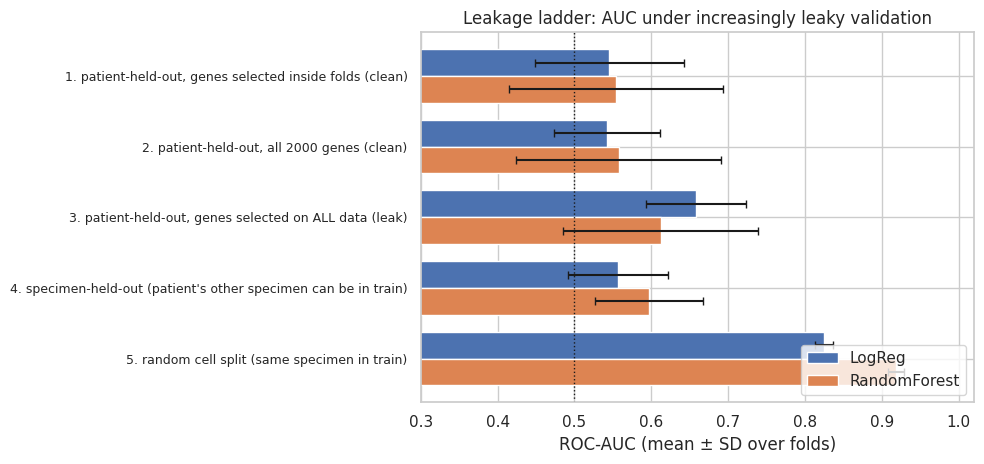

In [32]:
# ===== T3: leakage ladder - how much does each validation mistake inflate AUC? =====
LADDER_CELLS, FS_K = 100, 200
idxL = subsample_idx(LADDER_CELLS, seed=1)
XL, yL, gL, sL = Xmat[idxL], y[idxL], groups[idxL], sample_ids[idxL]
sel_all = SelectKBest(f_classif, k=FS_K).fit(XL, yL).get_support()                  # selection that SEES every label (leak)
RUNGS = {
    "1. patient-held-out, genes selected inside folds (clean)":   dict(split="patient",  X=XL,           fs=True),
    "2. patient-held-out, all 2000 genes (clean)":                dict(split="patient",  X=XL,           fs=False),
    "3. patient-held-out, genes selected on ALL data (leak)":     dict(split="patient",  X=XL[:, sel_all], fs=False),
    "4. specimen-held-out (patient's other specimen can be in train)":        dict(split="specimen", X=XL,           fs=False),
    "5. random cell split (same specimen in train)":              dict(split="cell",     X=XL,           fs=False),
}
LADDER_MODELS = [("LogReg", None), ("RandomForest", 100)]

def make_ladder_model(name, n_est, fs):
    m = make_model(name)
    if n_est: m.set_params(n_estimators=n_est)
    return Pipeline([("sel", SelectKBest(f_classif, k=FS_K)), ("model", m)]) if fs else m

def ladder_folds(rung, name, n_est):
    cfg = RUNGS[rung]; X = cfg["X"]; aucs = []
    for rep in range(N_REPEATS):
        seed = SEED + rep
        if cfg["split"] == "patient":  spl = StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed).split(X, yL, gL)
        elif cfg["split"] == "specimen": spl = StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed).split(X, yL, sL)
        else:                            spl = StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed).split(X, yL)
        for tr, te in spl:
            if len(np.unique(yL[te])) < 2: continue
            m = make_ladder_model(name, n_est, cfg["fs"]).fit(X[tr], yL[tr]); aucs.append(roc_auc_score(yL[te], m.predict_proba(X[te])[:, 1]))
    return aucs

rows = []
for rung in RUNGS:
    for name, n_est in LADDER_MODELS:
        a = cached(f"ladder_{rung[:1]}_{name}_{LADDER_CELLS}_{FS_K}_{N_REPEATS}", lambda: ladder_folds(rung, name, n_est))
        rows.append(dict(rung=rung, model=name, AUC_mean=np.mean(a), AUC_sd=np.std(a), n_folds=len(a)))
lad = pd.DataFrame(rows)
base = lambda pre: lad[lad.rung.str.startswith(pre)].set_index("model").AUC_mean
ref1, ref2 = base("1."), base("2.")                                                # rung 3 is compared with rung 1 (same gene selection, done properly)
lad["inflation_vs_clean"] = lad.apply(lambda r: r.AUC_mean - (ref1 if r.rung.startswith(("1.", "3.")) else ref2)[r.model], axis=1)
display(lad.round(3)); lad.to_csv(OUT_DIR / "leakage_ladder.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.8)); h = 0.38; yy = np.arange(len(RUNGS))
for k, (name, _) in enumerate(LADDER_MODELS):
    d = lad[lad.model == name].set_index("rung").loc[list(RUNGS)]
    ax.barh(yy + (k - 0.5) * h, d.AUC_mean, h, xerr=d.AUC_sd, label=name, color=["#4C72B0", "#DD8452"][k], capsize=3)
ax.axvline(0.5, color="k", ls=":", lw=1); ax.set_yticks(yy); ax.set_yticklabels(list(RUNGS), fontsize=9); ax.invert_yaxis()
ax.set_xlabel("ROC-AUC (mean ± SD over folds)"); ax.set_xlim(0.3, 1.02); ax.legend(loc="lower right"); ax.set_title("Leakage ladder: AUC under increasingly leaky validation")
plt.tight_layout(); savefig("ladder_01_leakage_ladder.png")


In [33]:
# ===== T3b: where does the leakage come from? (specimen vs patient vs feature selection) =====
L = lad.assign(rung_no=lad.rung.str[0]).pivot(index="model", columns="rung_no", values="AUC_mean")
dec = pd.DataFrame({
    "clean patient-held-out (rung 2)":                          L["2"],
    "+ patient's other specimen in train (rung 4 - 2)":         L["4"] - L["2"],
    "+ same specimen in train / random cell split (rung 5 - 4)": L["5"] - L["4"],
    "feature-selection leak (rung 3 - 1)":                      L["3"] - L["1"],
}).round(3)
display(dec); dec.to_csv(OUT_DIR / "leakage_decomposition.csv")
print("Reading: if 'rung 5 - 4' >> 'rung 4 - 2', the leak is SPECIMEN identity (library/batch), not patient identity across specimens.")

,clean patient-held-out (rung 2),+ patient's other specimen in train (rung 4 - 2),+ same specimen in train / random cell split (rung 5 - 4),feature-selection leak (rung 3 - 1)
model,,,,
LogReg,0.542,0.014,0.268,0.113
RandomForest,0.558,0.040,0.321,0.058


Reading: if 'rung 5 - 4' >> 'rung 4 - 2', the leak is SPECIMEN identity (library/batch), not patient identity across specimens.


### 4. Bootstrap confidence intervals and gap test

  loaded cache: bootstrap_1000_7707239b63d3.pkl


,model,AUC_cell,AUC_cell_CI,AUC_patient,AUC_patient_CI,gap,gap_CI,p_gap_le_0,boot_P_patientAUC_le_0p5
0,LogReg,0.886,0.859-0.911,0.558,0.482-0.631,0.328,0.269-0.390,0.001,0.062
1,ElasticNet,0.896,0.869-0.921,0.560,0.481-0.636,0.336,0.272-0.402,0.001,0.071
2,RandomForest,0.954,0.931-0.972,0.581,0.477-0.689,0.372,0.276-0.463,0.001,0.054
3,XGBoost,0.958,0.942-0.973,0.579,0.488-0.669,0.379,0.298-0.462,0.001,0.046


AUCs here are pooled out-of-fold AUCs (all held-out predictions together), so they differ slightly from the mean-of-folds AUCs in the main table.


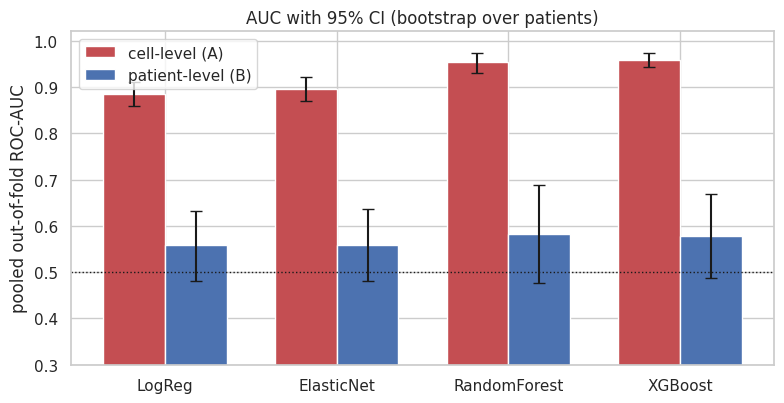

In [34]:
# ===== T4: patient-level bootstrap CIs + test of the cell-vs-patient gap (uses the saved out-of-fold predictions) =====
B_BOOT = 1000
def oof_prob(design, model):
    d = OOF[design]; d = d[d.model == model].groupby("idx").prob.mean()            # mean over repeats -> one prediction per cell
    out = np.full(len(y), np.nan); out[d.index.values] = d.values; return out
PR = {m: {dsg: oof_prob(dsg, m) for dsg in ("cell", "patient")} for m in MODELS_TO_RUN}
pats = np.unique(groups); cells_of = {p: np.where(groups == p)[0] for p in pats}

def run_boot():
    rng = np.random.RandomState(0); A = {m: [] for m in MODELS_TO_RUN}; Bp = {m: [] for m in MODELS_TO_RUN}
    for b in tqdm(range(B_BOOT), desc="bootstrap"):
        ii = np.concatenate([cells_of[p] for p in rng.choice(pats, len(pats), replace=True)])
        if len(np.unique(y[ii])) < 2: continue
        for m in MODELS_TO_RUN:
            A[m].append(roc_auc_score(y[ii], PR[m]["cell"][ii])); Bp[m].append(roc_auc_score(y[ii], PR[m]["patient"][ii]))
    return {m: (np.array(A[m]), np.array(Bp[m])) for m in MODELS_TO_RUN}
boot = cached(f"bootstrap_{B_BOOT}", run_boot)

rows = []
for m in MODELS_TO_RUN:
    a, b = boot[m]; gap = a - b; ci = lambda v: np.percentile(v, [2.5, 97.5])
    rows.append(dict(model=m, AUC_cell=roc_auc_score(y, PR[m]["cell"]), AUC_cell_CI=f"{ci(a)[0]:.3f}-{ci(a)[1]:.3f}",
                     AUC_patient=roc_auc_score(y, PR[m]["patient"]), AUC_patient_CI=f"{ci(b)[0]:.3f}-{ci(b)[1]:.3f}",
                     gap=roc_auc_score(y, PR[m]["cell"]) - roc_auc_score(y, PR[m]["patient"]), gap_CI=f"{ci(gap)[0]:.3f}-{ci(gap)[1]:.3f}",
                     p_gap_le_0=(1 + (gap <= 0).sum()) / (1 + len(gap)), boot_P_patientAUC_le_0p5=(b <= 0.5).mean()))
bt = pd.DataFrame(rows); display(bt.round(3)); bt.to_csv(OUT_DIR / "bootstrap_ci_patient_resampling.csv", index=False)
print("AUCs here are pooled out-of-fold AUCs (all held-out predictions together), so they differ slightly from the mean-of-folds AUCs in the main table.")

fig, ax = plt.subplots(figsize=(8, 4.2)); x = np.arange(len(MODELS_TO_RUN)); w = 0.36
for k, (lab, col, i) in enumerate([("cell-level (A)", "#C44E52", 0), ("patient-level (B)", "#4C72B0", 1)]):
    pt = [roc_auc_score(y, PR[m]["cell" if i == 0 else "patient"]) for m in MODELS_TO_RUN]
    lo = [np.percentile(boot[m][i], 2.5) for m in MODELS_TO_RUN]; hi = [np.percentile(boot[m][i], 97.5) for m in MODELS_TO_RUN]
    ax.bar(x + (k - 0.5) * w, pt, w, yerr=[np.array(pt) - lo, np.array(hi) - pt], capsize=4, color=col, label=lab)
ax.axhline(0.5, color="k", ls=":", lw=1); ax.set_xticks(x); ax.set_xticklabels(MODELS_TO_RUN); ax.set_ylabel("pooled out-of-fold ROC-AUC"); ax.set_ylim(0.3, 1.02)
ax.set_title("AUC with 95% CI (bootstrap over patients)"); ax.legend(loc="upper left"); plt.tight_layout(); savefig("ci_01_bootstrap_auc.png")

Learning curve/power analysis

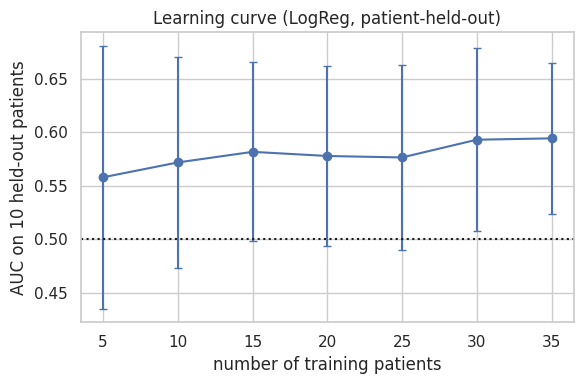

In [35]:
# ===== learning curve: patient-held-out AUC vs number of training patients =====
idx = subsample_idx(100, seed=3); Xs, ys, gs = Xmat[idx], y[idx], groups[idx]
pats = np.unique(gs); rows = []
for rep in range(20):
    perm = np.random.RandomState(rep).permutation(pats); te_p, rest = perm[:10], perm[10:]
    te = np.isin(gs, te_p)
    if len(np.unique(ys[te])) < 2: continue
    for k in (5, 10, 15, 20, 25, 30, 35):
        tr = np.isin(gs, rest[:k])
        if len(np.unique(ys[tr])) < 2: continue
        m = make_model("LogReg").fit(Xs[tr], ys[tr])
        rows.append(dict(n_train_patients=k, rep=rep, AUC=roc_auc_score(ys[te], m.predict_proba(Xs[te])[:, 1])))
lc = pd.DataFrame(rows); g = lc.groupby("n_train_patients").AUC.agg(["mean", "std"]).reset_index()
plt.figure(figsize=(6, 4)); plt.errorbar(g.n_train_patients, g["mean"], yerr=g["std"], marker="o", capsize=3)
plt.axhline(0.5, color="k", ls=":"); plt.xlabel("number of training patients"); plt.ylabel("AUC on 10 held-out patients")
plt.title("Learning curve (LogReg, patient-held-out)"); plt.tight_layout(); savefig("lc_01_learning_curve.png")
lc.to_csv(OUT_DIR / "learning_curve.csv", index=False)

### 5. Simulation: why cell-level CV leaks

  loaded cache: simulation_v2_7707239b63d3.pkl


,signal,patient_sd,model,cell,patient
0,0.0,0.0,LogReg,0.506,0.496
1,0.0,0.0,RandomForest,0.507,0.506
2,0.0,0.5,LogReg,0.811,0.481
3,0.0,0.5,RandomForest,0.809,0.485
4,0.0,1.0,LogReg,0.969,0.514
5,0.0,1.0,RandomForest,0.997,0.491
6,0.0,2.0,LogReg,0.998,0.492
7,0.0,2.0,RandomForest,1.000,0.452
8,0.5,0.0,LogReg,0.757,0.752
9,0.5,0.0,RandomForest,0.723,0.720


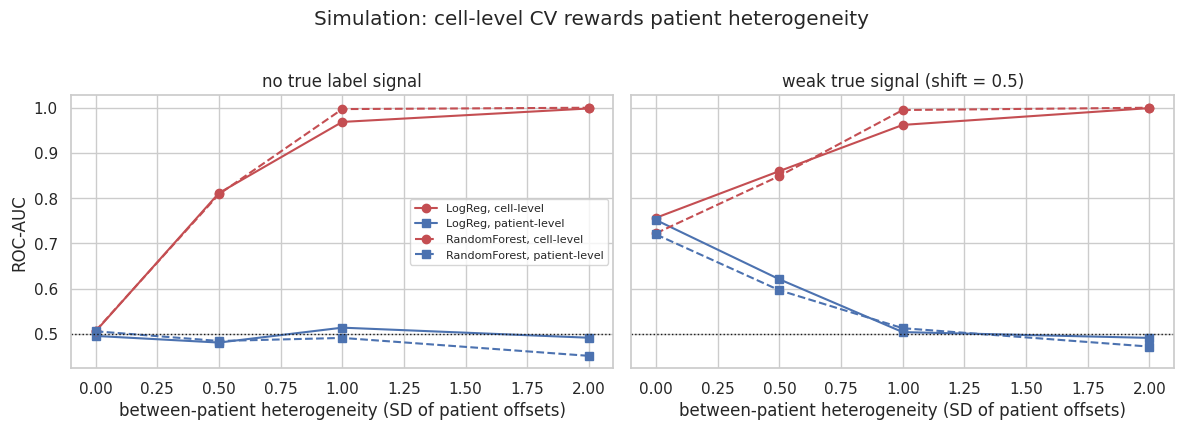

In [36]:
# ===== T5: simulation - label-free data with patient effects; shows WHY cell-level CV leaks =====
def simulate(patient_sd, signal, seed, P=45, n_cells=60, G=100, n_inf=5):
    r = np.random.RandomState(seed); yp = (r.rand(P) < 0.6).astype(int)
    yp[:2] = [0, 1]                                                       # both classes always present
    pat = np.repeat(np.arange(P), n_cells); yc = yp[pat]
    X = r.randn(P * n_cells, G) + r.randn(P, G)[pat] * patient_sd          # cell noise + patient-specific offsets
    X[:, :n_inf] += signal * yc[:, None]                                  # real label signal (0 = none)
    return X.astype(np.float32), yc, pat

def sim_auc(name, patient_sd, signal, seed):
    X, yc, pat = simulate(patient_sd, signal, seed); out = {}
    for design in ("cell", "patient"):
        spl = (StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed).split(X, yc) if design == "cell"
               else StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed).split(X, yc, pat))
        a = []
        for tr, te in spl:
            if len(np.unique(yc[te])) < 2: continue
            m = make_model(name)
            if name == "RandomForest": m.set_params(n_estimators=50)
            m.fit(X[tr], yc[tr]); a.append(roc_auc_score(yc[te], m.predict_proba(X[te])[:, 1]))
        out[design] = np.mean(a)
    return out

def run_sim():
    rows = []
    for signal in (0.0, 0.5):
        for psd in (0.0, 0.5, 1.0, 2.0):
            for name in ("LogReg", "RandomForest"):
                for seed in range(5):
                    r = sim_auc(name, psd, signal, seed + 1000 * int(signal * 10) + 100 * int(psd * 10))   # independent draw per setting
                    rows.append(dict(signal=signal, patient_sd=psd, model=name, seed=seed, cell=r["cell"], patient=r["patient"]))
    return pd.DataFrame(rows)
sim = cached("simulation_v2", run_sim)
simg = sim.groupby(["signal", "patient_sd", "model"])[["cell", "patient"]].mean().reset_index(); display(simg.round(3))
simg.to_csv(OUT_DIR / "simulation_leakage.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, signal in zip(axes, (0.0, 0.5)):
    for name, ls in (("LogReg", "-"), ("RandomForest", "--")):
        d = simg[(simg.signal == signal) & (simg.model == name)]
        ax.plot(d.patient_sd, d.cell, ls, marker="o", color="#C44E52", label=f"{name}, cell-level")
        ax.plot(d.patient_sd, d.patient, ls, marker="s", color="#4C72B0", label=f"{name}, patient-level")
    ax.axhline(0.5, color="k", ls=":", lw=1); ax.set_xlabel("between-patient heterogeneity (SD of patient offsets)")
    ax.set_title("no true label signal" if signal == 0 else f"weak true signal (shift = {signal})")
axes[0].set_ylabel("ROC-AUC"); axes[0].legend(fontsize=8); plt.suptitle("Simulation: cell-level CV rewards patient heterogeneity", y=1.02); plt.tight_layout()
savefig("sim_01_leakage_vs_heterogeneity.png")

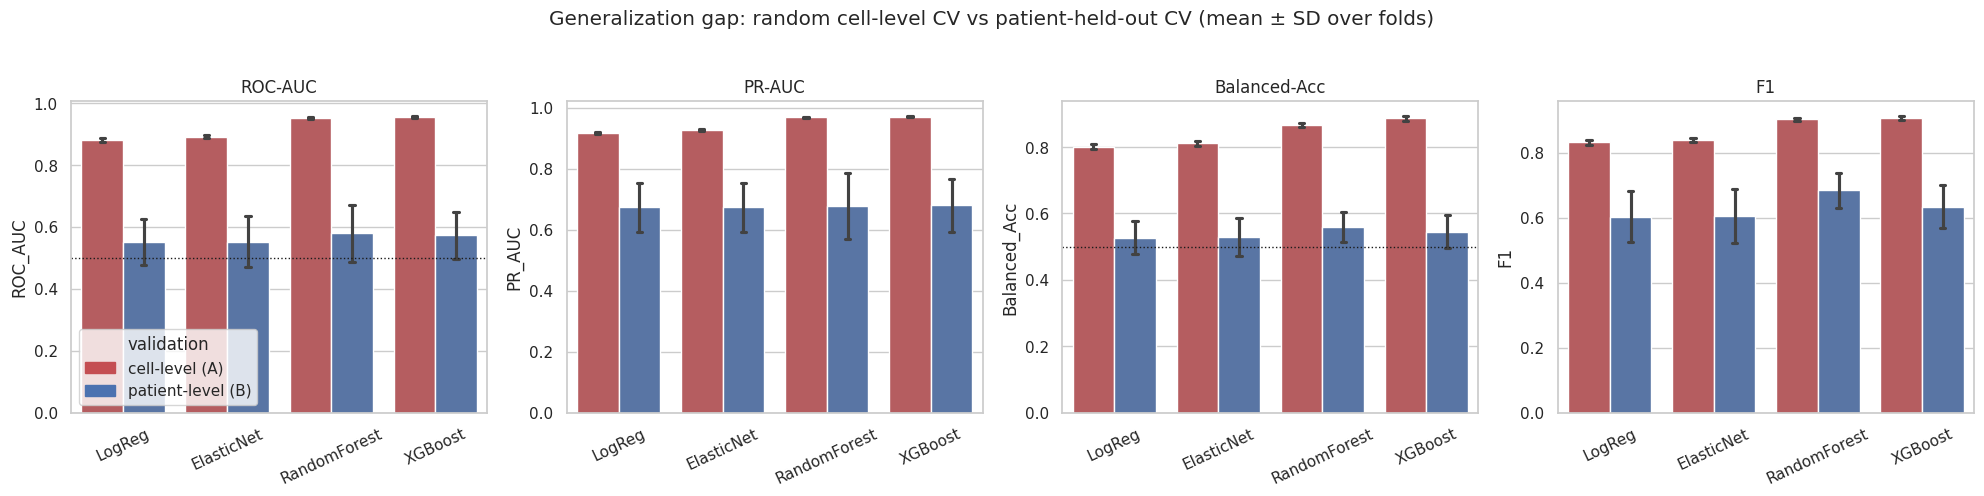

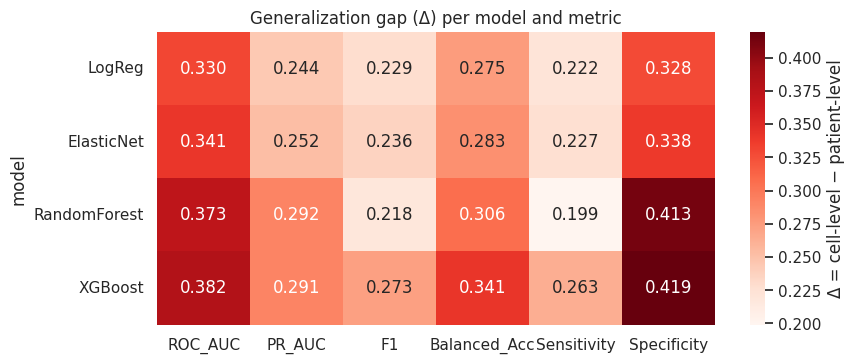

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, k in zip(axes, ["ROC_AUC", "PR_AUC", "Balanced_Acc", "F1"]):
    sns.barplot(data=results, x="model", y=k, hue="design", hue_order=["cell", "patient"], palette=["#C44E52", "#4C72B0"], errorbar="sd", ax=ax, capsize=0.1)
    ax.set_title(k.replace("_", "-")); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
    if k in ("ROC_AUC", "Balanced_Acc"): ax.axhline(0.5, color="k", ls=":", lw=1)
    if k != "ROC_AUC": ax.get_legend().remove()
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color="#C44E52"), Patch(color="#4C72B0")], labels=["cell-level (A)", "patient-level (B)"], title="validation")
plt.suptitle("Generalization gap: random cell-level CV vs patient-held-out CV (mean ± SD over folds)", y=1.03); plt.tight_layout()
savefig("results_01_cell_vs_patient.png")

gap = summary[[f"{k}_gap(A-B)" for k in ["ROC_AUC", "PR_AUC", "F1", "Balanced_Acc", "Sensitivity", "Specificity"]]]
gap.columns = [c.replace("_gap(A-B)", "") for c in gap.columns]
plt.figure(figsize=(9, 3.8)); sns.heatmap(gap, annot=True, fmt=".3f", cmap="Reds", cbar_kws={"label": "Δ = cell-level − patient-level"})
plt.title("Generalization gap (Δ) per model and metric"); savefig("results_02_gap_heatmap.png")

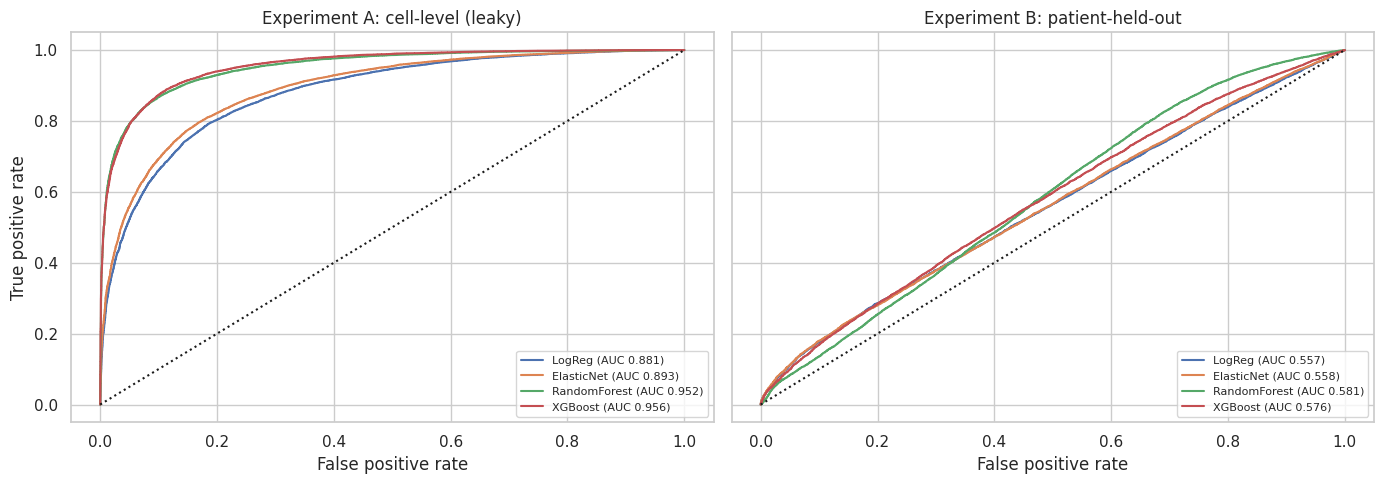

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (design, title) in zip(axes, [("cell", "Experiment A: cell-level (leaky)"), ("patient", "Experiment B: patient-held-out")]):
    d = OOF[design]
    for m in MODELS_TO_RUN:
        s = d[d.model == m]; fpr, tpr, _ = roc_curve(s.y, s.prob)
        ax.plot(fpr, tpr, label=f"{m} (AUC {roc_auc_score(s.y, s.prob):.3f})")
    ax.plot([0, 1], [0, 1], "k:"); ax.set_title(title); ax.set_xlabel("False positive rate"); ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("True positive rate"); plt.tight_layout(); savefig("results_03_roc_pooled_oof.png")

In [39]:
# ------------ tumour(sample)-level view: average the cell probabilities per specimen ------------
rows = []
for design in ["cell", "patient"]:
    d = OOF[design].copy(); d["sample"] = sample_ids[d.idx.values]
    for m in MODELS_TO_RUN:
        s = d[d.model == m].groupby("sample").agg(prob=("prob", "mean"), y=("y", "first"))
        rows.append({"design": design, "model": m, "n_samples": len(s), "sample_ROC_AUC": roc_auc_score(s.y, s.prob),
                     "sample_accuracy": ((s.prob >= 0.5).astype(int) == s.y).mean()})
sample_level = pd.DataFrame(rows).pivot(index="model", columns="design", values=["sample_ROC_AUC", "sample_accuracy"])
display(sample_level.round(3)); sample_level.round(4).to_csv(OUT_DIR / "sample_level_aggregated.csv")

sample_ROC_AUC         sample_accuracy        
design                 cell patient            cell patient
model                                                      
ElasticNet            1.000   0.602           0.984   0.594
LogReg                1.000   0.604           0.984   0.578
RandomForest          0.993   0.633           0.938   0.688
XGBoost               1.000   0.631           0.984   0.609

## 7. Exploratory gene stability, SHAP and pathways

Gene importance and pathway results are exploratory. The original importance rankings are based on the global-HVG analysis unless regenerated from the fold-internal analysis. Compare observed Jaccard stability with a label-permuted null before interpreting stability. Use the 2,000-HVG feature universe as the enrichment background for a global-HVG gene list; do not use all genes in `adata_full` as the background for a list selected from 2,000 HVGs.


,design,model,n_folds,mean_pairwise_Jaccard_topK,genes_in_>=60%_of_folds
1,cell,ElasticNet,10,0.694,94
5,patient,ElasticNet,10,0.389,80
0,cell,LogReg,10,0.654,88
4,patient,LogReg,10,0.373,75
2,cell,RandomForest,10,0.822,95
6,patient,RandomForest,10,0.570,91
3,cell,XGBoost,10,0.569,77
7,patient,XGBoost,10,0.352,68


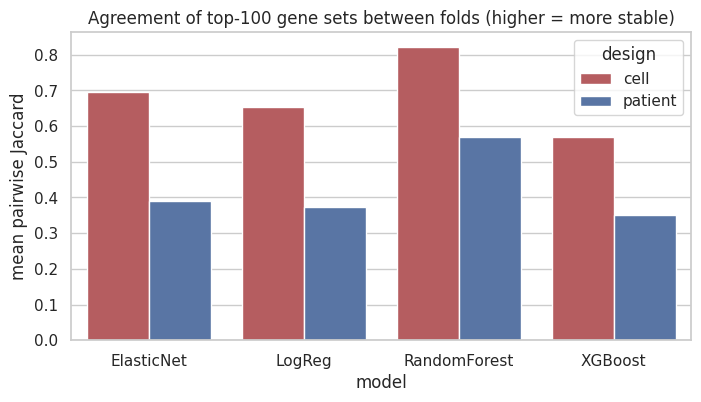

In [40]:
def top_sets(M, k): return [set(np.argsort(-row)[:k]) for row in M]
def mean_jaccard(sets):
    pairs = list(itertools.combinations(sets, 2)); return np.mean([len(a & b) / len(a | b) for a, b in pairs])
def freq_vector(M, k):
    f = np.zeros(M.shape[1])
    for s in top_sets(M, k): f[list(s)] += 1
    return f / M.shape[0]

stab_rows, FREQ = [], {}
for (design, m), M in IMP.items():
    f = freq_vector(M, TOP_K_GENES); FREQ[(design, m)] = f
    stab_rows.append({"design": design, "model": m, "n_folds": M.shape[0], "mean_pairwise_Jaccard_topK": mean_jaccard(top_sets(M, TOP_K_GENES)),
                      f"genes_in_>={int(STABLE_MIN_FREQ*100)}%_of_folds": int((f >= STABLE_MIN_FREQ).sum())})
stab = pd.DataFrame(stab_rows).sort_values(["model", "design"]); display(stab.round(3)); stab.round(4).to_csv(OUT_DIR / "feature_stability_summary.csv", index=False)

plt.figure(figsize=(8, 4)); sns.barplot(data=stab, x="model", y="mean_pairwise_Jaccard_topK", hue="design", hue_order=["cell", "patient"], palette=["#C44E52", "#4C72B0"])
plt.title(f"Agreement of top-{TOP_K_GENES} gene sets between folds (higher = more stable)"); plt.ylabel("mean pairwise Jaccard"); savefig("results_04_feature_stability.png")

best model under patient-level validation: RandomForest
stable genes (RandomForest, >= 60% of patient-held-out folds): 91
genes stable in >= 2 models: 84
overlap of stable sets (cell-level folds vs patient-level folds): 87 shared | 8 only cell-level | 4 only patient-level


,gene,freq_patient_folds,freq_cell_folds,mean_norm_importance,n_models_stable
1969,CH507-528H12.1,1.0,1.0,0.026,4
1968,CH507-513H4.1,1.0,1.0,0.022,4
1562,PLCG2,1.0,1.0,0.016,4
434,KCNIP4,1.0,1.0,0.015,4
356,CADM2,1.0,1.0,0.013,4
1506,RBFOX1,1.0,1.0,0.008,4
148,MDM4,1.0,1.0,0.008,4
1108,CRYAB,1.0,1.0,0.008,4
691,FAM20C,1.0,1.0,0.007,2
23,KAZN,1.0,1.0,0.007,3


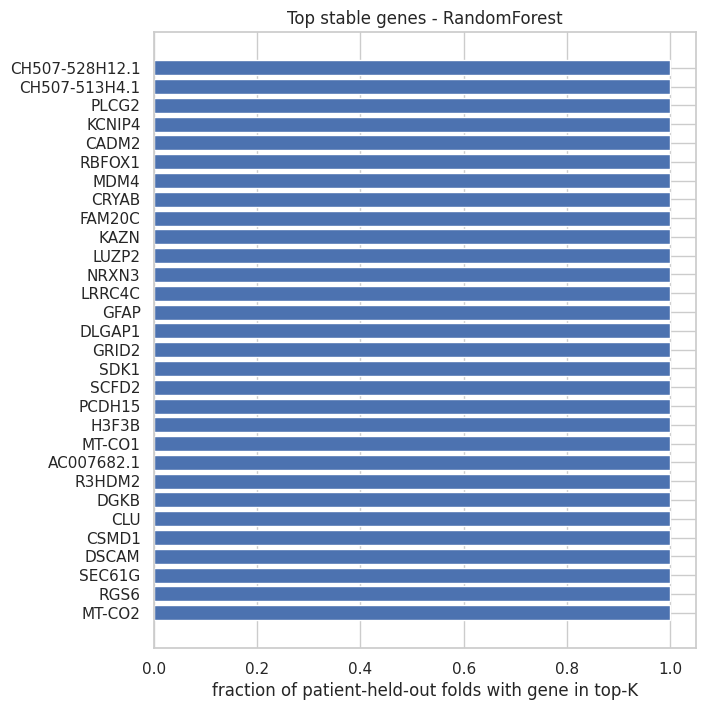

In [41]:
best_model = results[results.design == "patient"].groupby("model")["ROC_AUC"].mean().idxmax()
print("best model under patient-level validation:", best_model)
M = IMP[("patient", best_model)]; f = FREQ[("patient", best_model)]
mean_norm_imp = (M / M.sum(1, keepdims=True)).mean(0)
gene_tbl = pd.DataFrame({"gene": genes, "freq_patient_folds": f, "freq_cell_folds": FREQ[("cell", best_model)], "mean_norm_importance": mean_norm_imp})
# consensus across all four models (patient-level)
gene_tbl["n_models_stable"] = sum((FREQ[("patient", m)] >= STABLE_MIN_FREQ).astype(int) for m in MODELS_TO_RUN)
gene_tbl = gene_tbl.sort_values(["freq_patient_folds", "mean_norm_importance"], ascending=False)
gene_tbl.to_csv(OUT_DIR / "gene_stability_table.csv", index=False)
stable_genes = gene_tbl.loc[gene_tbl.freq_patient_folds >= STABLE_MIN_FREQ, "gene"].tolist()
consensus_genes = gene_tbl.loc[gene_tbl.n_models_stable >= 2, "gene"].tolist()
print(f"stable genes ({best_model}, >= {STABLE_MIN_FREQ:.0%} of patient-held-out folds): {len(stable_genes)}")
print(f"genes stable in >= 2 models: {len(consensus_genes)}")
cell_stable = set(gene_tbl.loc[gene_tbl.freq_cell_folds >= STABLE_MIN_FREQ, "gene"])
print(f"overlap of stable sets (cell-level folds vs patient-level folds): {len(cell_stable & set(stable_genes))} shared | "
      f"{len(cell_stable - set(stable_genes))} only cell-level | {len(set(stable_genes) - cell_stable)} only patient-level")
display(gene_tbl.head(25).round(3))

top = gene_tbl.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 8)); ax.barh(top.gene, top.freq_patient_folds, color="#4C72B0")
ax.set_xlabel("fraction of patient-held-out folds with gene in top-K"); ax.set_title(f"Top stable genes - {best_model}"); savefig("results_05_top_stable_genes.png")

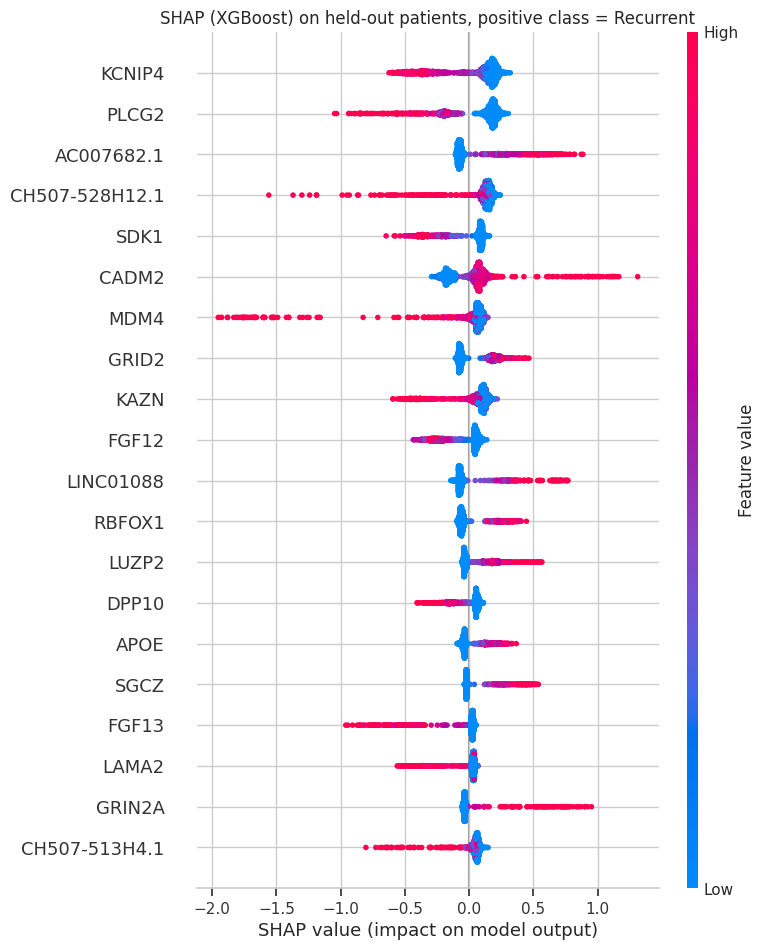

In [42]:
# ---------------- SHAP on a patient-held-out fold (XGBoost built-in contributions) ----------------
if RUN_SHAP:
    try:
        import xgboost as xgb, shap
        tr, te = next(iter(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(Xmat, y, groups)))
        m = make_model("XGBoost"); m.set_params(scale_pos_weight=(y[tr] == 0).sum() / max(1, (y[tr] == 1).sum()))
        m.fit(Xmat[tr], y[tr])
        te_s = np.random.RandomState(SEED).choice(te, min(1500, len(te)), replace=False)
        sv = m.get_booster().predict(xgb.DMatrix(Xmat[te_s]), pred_contribs=True)[:, :-1]   # last column = bias term
        shap.summary_plot(sv, Xmat[te_s], feature_names=genes, max_display=20, show=False)
        plt.title(f"SHAP (XGBoost) on held-out patients, positive class = {POSITIVE_LABEL}"); savefig("results_06_shap_patient_heldout.png")
        pd.DataFrame({"gene": genes, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False).to_csv(OUT_DIR / "shap_importance_heldout_fold.csv", index=False)
    except Exception as e:
        print("SHAP step skipped:", repr(e))

,source,native,name,p_value,intersection_size,term_size


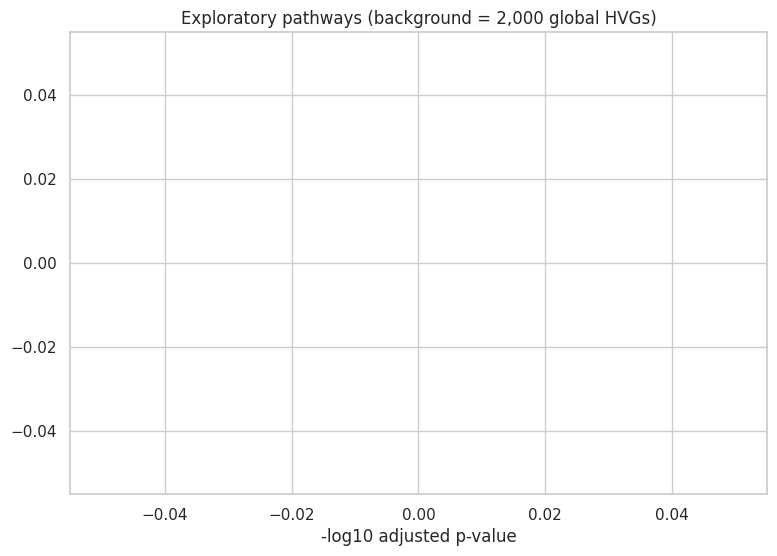

In [43]:
# ---------------- pathway enrichment (g:Profiler) ----------------
# Exploratory only: selected from the global-HVG model. Use the same 2,000-HVG
# universe as the enrichment background, not all genes in adata_full.
enr = None
if RUN_ENRICHMENT:
    query = stable_genes if len(stable_genes) >= 10 else gene_tbl.head(100).gene.tolist()
    if len(stable_genes) < 10: print(f"only {len(stable_genes)} stable genes -> using the top-100 genes by stability instead")
    try:
        from gprofiler import GProfiler
        gp = GProfiler(return_dataframe=True)
        enr = gp.profile(organism="hsapiens", query=query, background=list(genes), sources=["GO:BP","KEGG","REAC"],
                 significance_threshold_method="g_SCS", user_threshold=0.05, no_evidences=False)
        if enr is not None and len(enr) and "effective_domain_size" in enr: print("effective domain size:", int(enr.effective_domain_size.iloc[0]), "(should be <= ~2000, else the background was ignored)")
        else:
            enr.to_csv(OUT_DIR / "pathway_enrichment_gprofiler.csv", index=False)
            display(enr[["source", "native", "name", "p_value", "intersection_size", "term_size"]].head(15))
            t = enr.sort_values("p_value").head(15).iloc[::-1]
            plt.figure(figsize=(9, 6)); plt.barh(t.name.str.slice(0, 60), -np.log10(t.p_value), color="#55A868")
            plt.xlabel("-log10 adjusted p-value"); plt.title("Exploratory pathways (background = 2,000 global HVGs)"); savefig("results_07_pathways.png")
    except Exception as e:
        print("g:Profiler unavailable (needs internet):", repr(e))
        print("Fallback: copy this list into https://biit.cs.ut.ee/gprofiler or https://maayanlab.cloud/Enrichr :\n", "\n".join(query))


Multi testing correction table

In [44]:
# ===== Pre-declared six-test family: one primary test + five secondary tests =====
from statsmodels.stats.multitest import multipletests
tests = pd.DataFrame(
    [("Primary: patient-held-out LogReg", perm_LR[2], "Primary"),
     ("Secondary: patient-held-out RandomForest", perm_RF[2], "Secondary")]
  + [(f"Secondary: paired patients {r.model}", r.p_value, "Secondary") for r in paired_df.itertuples()]
  + [(f"Secondary: pseudobulk {r.model}", r.p_value, "Secondary") for r in pb_df.itertuples()],
    columns=["test", "p_raw", "analysis_role"])
assert len(tests) == 6, f"Expected the pre-declared six-test family; found {len(tests)} tests."
tests["p_holm"] = multipletests(tests.p_raw, method="holm")[1]
tests["q_BH"] = multipletests(tests.p_raw, method="fdr_bh")[1]
tests["holm_reject_0.05"] = tests["p_holm"] < 0.05
display(tests.round(4))
tests.to_csv(OUT_DIR / "multiple_testing_correction.csv", index=False)
print("Primary inferential test: patient-held-out Logistic Regression. Interpret significance using Holm-adjusted p-values.")
print("No raw p-value is called significant unless its Holm-adjusted p-value is < 0.05.")


,test,p_raw,analysis_role,p_holm,q_BH,holm_reject_0.05
0,Primary: patient-held-out LogReg,0.1642,Primary,0.3861,0.1642,False
1,Secondary: patient-held-out RandomForest,0.1287,Secondary,0.3861,0.1642,False
2,Secondary: paired patients LogReg,0.0398,Secondary,0.2388,0.1188,False
3,Secondary: paired patients RandomForest,0.0594,Secondary,0.2388,0.1188,False
4,Secondary: pseudobulk LogReg,0.1592,Secondary,0.3861,0.1642,False
5,Secondary: pseudobulk RandomForest,0.0398,Secondary,0.2388,0.1188,False


Primary inferential test: patient-held-out Logistic Regression. Interpret significance using Holm-adjusted p-values.
No raw p-value is called significant unless its Holm-adjusted p-value is < 0.05.


In [45]:
# ---------------- cautious, data-driven summary text ----------------
best_cell = results[results.design == "cell"].groupby("model").ROC_AUC.mean().idxmax()
best_model = results[results.design == "patient"].groupby("model").ROC_AUC.mean().idxmax()
summary_text = (
    f"The retained analysis matrix contains {Xmat.shape[0]:,} nuclei from {len(np.unique(groups))} patient groups "
    f"and {Xmat.shape[1]} globally selected HVGs. In the global-HVG sensitivity analysis, the highest mean "
    f"cell-level ROC-AUC was {results[results.design=='cell'].ROC_AUC.max():.3f} ({best_cell}); the highest "
    f"mean patient-held-out ROC-AUC was {results[results.design=='patient'].ROC_AUC.max():.3f} ({best_model}). "
    "The global-HVG analysis is not fully leakage-free because feature selection used all retained nuclei. "
    "The fold-internal analysis appended below should be used as the primary estimate of unseen-patient performance. "
    "Gene rankings and enrichment are exploratory; they are not validated biomarkers."
)
if "tests" in globals():
    summary_text += f" The pre-declared family contains {len(tests)} tests; the minimum Holm-adjusted p-value is {tests.p_holm.min():.4f}. "
    summary_text += "No test is described as significant unless its Holm-adjusted p-value is below 0.05."
print(summary_text)
(OUT_DIR / "auto_summary_cautious.txt").write_text(summary_text)


The retained analysis matrix contains 17,965 nuclei from 45 patient groups and 2000 globally selected HVGs. In the global-HVG sensitivity analysis, the highest mean cell-level ROC-AUC was 0.960 (XGBoost); the highest mean patient-held-out ROC-AUC was 0.694 (RandomForest). The global-HVG analysis is not fully leakage-free because feature selection used all retained nuclei. The fold-internal analysis appended below should be used as the primary estimate of unseen-patient performance. Gene rankings and enrichment are exploratory; they are not validated biomarkers. The pre-declared family contains 6 tests; the minimum Holm-adjusted p-value is 0.2388. No test is described as significant unless its Holm-adjusted p-value is below 0.05.


738

## Interpretation cautions (retain in the report)

* **Recurrent ≠ therapy-resistant.** The label is a disease timepoint (primary vs treatment-exposed recurrent); it is not a direct drug-resistance label.
* **Tumor specimen ≠ verified malignant nucleus.** The loader retains nuclei tagged `Tumor` in a specimen-level tumor/normal metadata file and assigns that value to each retained row. Unless independently supported by cell-type annotation, CNV inference or validated marker evidence, write “nuclei from tumor specimens.”
* **Importance ≠ causation or biomarker validation.** Stable genes and pathways are exploratory associations in this cohort and require independent validation.
* **Global HVGs are not fold-internal.** The original 2,000 HVGs are selected using all retained cells. Those results are a sensitivity analysis; use the added fold-internal pipeline for the primary unseen-patient estimate.
* **Patient-held-out validation:** assert no patient overlap in every outer fold. The cohort includes unpaired patients; do not state that every patient contributes both classes.
* **Limits:** per-specimen cell cap (`MAX_CELLS_PER_SAMPLE`), within-cohort validation only, modest patient count, possible ambient RNA/neuronal contamination and composition effects, fixed 0.5 classification threshold, and no demonstrated clinical utility.


## 8. Required audit and corrected validation additions

The following cells preserve the title, RQs and four classical models. They add checks that were missing or incomplete in the original analysis. The fold-internal pipeline is a distinct analysis and does not overwrite the original global-HVG results.


### 8.1 Cohort attrition, per-specimen counts and label audit

In [46]:
# ===================== Cohort flow & specimen attrition =====================
# NOTE: uses adata_full everywhere (`adata` is deleted in cell 31 to free memory).

flow_rows = []
def _flow(stage, n_specimens=None, n_patients=None, n_cells=None, reason=""):
    flow_rows.append({"stage": stage, "specimens": n_specimens, "patients": n_patients,
                      "nuclei": n_cells, "definition_or_reason": reason})

_flow("GEO records before status/ATAC filtering",
      n_specimens=globals().get("N_GEO_SPECIMENS_ALL"),
      reason="GEOparse sample records; includes records later excluded by status/title")
_flow("GEO primary/recurrent snRNA specimens",
      n_specimens=globals().get("N_GEO_STATUS_SPECIMENS"),
      n_patients=(GEO.patient.nunique() if "GEO" in globals() and "patient" in GEO else None),
      reason="After retaining Primary/Recurrent and excluding ATAC records")
_flow("Expression GSM records loaded",
      n_specimens=globals().get("LOADED_SPECIMENS_BEFORE_QC"),
      n_patients=globals().get("LOADED_PATIENTS_BEFORE_QC"),
      n_cells=globals().get("LOADED_CELLS_BEFORE_QC"),
      reason="Matrix files successfully read and concatenated; failed/missing files are not counted")
_flow("Unique specimen IDs before QC filters",
      n_specimens=globals().get("PRE_FILTER_SPECIMENS"),
      n_patients=globals().get("PRE_FILTER_PATIENTS"),
      n_cells=globals().get("PRE_FILTER_CELLS"),
      reason="Unique sample/specimen IDs after concatenating loaded matrices")
_flow("After tumor-specimen metadata selection",
      N_SPEC_AFTER_TUMOR, N_PAT_AFTER_TUMOR, N_AFTER_TUMOR_SELECTION,
      "Rows kept by the Tumor flag; loader already filtered, so Part 3 selection removed nothing")
_flow("After minimum-nuclei specimen filter",
      N_SPEC_AFTER_MIN, N_PAT_AFTER_MIN, n_before_cap,
      f"< {MIN_CELLS_PER_SAMPLE} nuclei removed")
_flow("Final after per-specimen cap",
      adata_full.obs.sample_id.nunique(), adata_full.obs.patient.nunique(), adata_full.n_obs,
      f"cap {MAX_CELLS_PER_SAMPLE}/specimen, seed {SEED}; loader also capped at {LOAD_CAP_PER_SAMPLE}/file")

cohort_flow = pd.DataFrame(flow_rows)
display(cohort_flow)
cohort_flow.to_csv(OUT_DIR / "cohort_attrition_flow.csv", index=False)

# ---- per-specimen retained counts and patient mapping (built once, from adata_full) ----
specimen_counts = (adata_full.obs
                   .groupby(["sample_id", "patient", "status"], observed=True)
                   .size().rename("retained_nuclei").reset_index())
specimen_counts["is_paired_patient"] = specimen_counts.patient.map(
    adata_full.obs.groupby("patient", observed=True).status.nunique().eq(2))
display(specimen_counts.sort_values(["patient", "status"]))
specimen_counts.to_csv(OUT_DIR / "specimen_patient_cell_counts.csv", index=False)

# ---- reason for every GEO specimen that did not reach the model ----
_logd = pd.DataFrame(log, columns=["file", "n_barcodes", "n_tumour_in_meta", "key_prefix"])
_logd["gsm"] = _logd.file.str.split("_").str[0]
fate = GEO[["sf", "status", "patient"]].join(
    _logd.groupby("gsm").agg(n_files=("file", "size"), tumour_in_meta=("n_tumour_in_meta", "sum")))
fate[["n_files", "tumour_in_meta"]] = fate[["n_files", "tumour_in_meta"]].fillna(0).astype(int)

_loaded = set(SAMPLE_COUNTS_BEFORE_TUMOR_FILTER.index)
_kept   = set(adata_full.obs["sample_id"])

def _why(r):
    if r.n_files == 0:          return "no matrix file"
    if r.tumour_in_meta == 0:   return "0 Tumor nuclei in author metadata (all Normal OR ID mismatch - check)"
    if r.sf not in _loaded:     return "file present but not loaded"
    if r.sf not in _kept:       return f"< {MIN_CELLS_PER_SAMPLE} nuclei"
    return "kept"

fate["fate"] = fate.apply(_why, axis=1)
display(fate.fate.value_counts())
fate.to_csv(OUT_DIR / "gsm_fate_table.csv")

print("Dropped for minimum nuclei:", globals().get("N_SAMPLES_DROPPED_MIN_CELLS", "not recorded"),
      "specimens /", globals().get("N_CELLS_DROPPED_MIN_CELLS", "not recorded"), "nuclei")
print("Failed matrix files recorded in loader:",
      len(failed) if "failed" in globals() else "not available")
print("Note: unmatched GEO files and failed matrix files are separate from QC exclusions.")

# ---- specimen-level attrition ledger (each column = nuclei per specimen at that stage; NaN = absent) ----
series_to_join = []
for nm in ["SAMPLE_COUNTS_BEFORE_TUMOR_FILTER", "SAMPLE_COUNTS_AFTER_TUMOR_FILTER", "SAMPLE_COUNTS_AFTER_CAP"]:
    if nm in globals():
        series_to_join.append(globals()[nm].rename(nm))

if series_to_join:
    sample_attrition = pd.concat(series_to_join, axis=1)
    _col = lambda nm: sample_attrition[nm] if nm in sample_attrition else pd.Series(np.nan, index=sample_attrition.index)

    sample_attrition["lost_at_tumour_filter"]   = _col("SAMPLE_COUNTS_BEFORE_TUMOR_FILTER").notna() & _col("SAMPLE_COUNTS_AFTER_TUMOR_FILTER").isna()
    sample_attrition["dropped_below_minimum"]   = _col("SAMPLE_COUNTS_AFTER_TUMOR_FILTER").notna() & _col("SAMPLE_COUNTS_AFTER_CAP").isna()
    sample_attrition["retained_final"]          = _col("SAMPLE_COUNTS_AFTER_CAP").notna()

    display(sample_attrition)

,stage,specimens,patients,nuclei,definition_or_reason
0,GEO records before status/ATAC filtering,113,NaN,NaN,GEOparse sample records; includes records late...
1,GEO primary/recurrent snRNA specimens,103,57.0,NaN,After retaining Primary/Recurrent and excludin...
2,Expression GSM records loaded,70,46.0,34672.0,Matrix files successfully read and concatenate...
3,Unique specimen IDs before QC filters,67,46.0,34672.0,Unique sample/specimen IDs after concatenating...
4,After tumor-specimen metadata selection,67,46.0,34672.0,Rows kept by the Tumor flag; loader already fi...
5,After minimum-nuclei specimen filter,64,45.0,34615.0,< 30 nuclei removed
6,Final after per-specimen cap,64,45.0,17965.0,"cap 300/specimen, seed 42; loader also capped ..."


,sample_id,patient,status,retained_nuclei,is_paired_patient
1,SF10108,pair1,Recurrent,300,False
48,SF4849,pair10,Primary,300,True
51,SF6118,pair10,Recurrent,234,True
49,SF5581,pair11,Primary,300,True
61,SF9715,pair11,Recurrent,300,True
...,...,...,...,...,...
28,SF12594,solo_SF12594,Recurrent,300,False
29,SF12616,solo_SF12616,Primary,294,False
30,SF12704,solo_SF12704,Recurrent,300,False
31,SF12707,solo_SF12707,Primary,300,False


,count
fate,
kept,67
no matrix file,20
0 Tumor nuclei in author metadata (all Normal OR ID mismatch - check),13
< 30 nuclei,3


Dropped for minimum nuclei: 3 specimens / 57 nuclei
Failed matrix files recorded in loader: 0
Note: unmatched GEO files and failed matrix files are separate from QC exclusions.


,SAMPLE_COUNTS_BEFORE_TUMOR_FILTER,SAMPLE_COUNTS_AFTER_TUMOR_FILTER,SAMPLE_COUNTS_AFTER_CAP,lost_at_tumour_filter,dropped_below_minimum,retained_final
sample_id,,,,,,
SF10099,450,450,300.0,False,False,True
SF10108,600,600,300.0,False,False,True
SF10432,600,600,300.0,False,False,True
SF10433,502,502,300.0,False,False,True
SF10441,467,467,300.0,False,False,True
...,...,...,...,...,...,...
SF9510,600,600,300.0,False,False,True
SF9715,1200,1200,300.0,False,False,True
SF9798,600,600,300.0,False,False,True


### 8.2 Is the tumor label cell-level malignancy evidence?

In [47]:
# This explicitly tests whether Tumor_Normal_annotation is constant in the retained rows.
if "Tumor_Normal_annotation" in adata_full.obs.columns:
    tumor_values = adata_full.obs["Tumor_Normal_annotation"].astype(str).value_counts(dropna=False)
    print(tumor_values)
    print("Unique values:", adata_full.obs["Tumor_Normal_annotation"].nunique(dropna=False))
    print("Constant column:", adata_full.obs["Tumor_Normal_annotation"].nunique(dropna=False) == 1)
else:
    print("Tumor_Normal_annotation is not present in adata_full.obs.")

# Descriptive marker audit only. These markers do NOT establish malignancy by themselves.
marker_groups = {
    "GBM/tumor-associated (illustrative)": ["EGFR", "SOX2", "OLIG2", "CHI3L1", "CD44", "GFAP"],
    "neuronal/synaptic contamination context": ["SNAP25", "SYT1", "RBFOX3", "NEFL", "NEFM", "SLC17A7"],
    "myeloid/immune context": ["PTPRC", "AIF1", "TYROBP", "LST1"],
}
available = set(adata_full.var_names.astype(str))
marker_rows = []
for group_name, marker_list in marker_groups.items():
    found = [g for g in marker_list if g in available]
    marker_rows.append({"marker_group": group_name, "requested": len(marker_list),
                        "found_in_expression": len(found), "genes_found": ", ".join(found)})
marker_audit = pd.DataFrame(marker_rows)
display(marker_audit)
marker_audit.to_csv(OUT_DIR / "marker_availability_audit.csv", index=False)

print("Interpretation rule: marker availability/mean expression is a plausibility check, not proof of malignant identity.")
print("For a defensible malignant-cell claim, use the source study's cell-type annotation and/or CNV-based malignant-cell evidence if available.")
print("If those are unavailable, use: 'nuclei retained from tumor specimens' throughout.")


Tumor_Normal_annotation
Tumor    17965
Name: count, dtype: int64
Unique values: 1
Constant column: True


,marker_group,requested,found_in_expression,genes_found
0,GBM/tumor-associated (illustrative),6,6,"EGFR, SOX2, OLIG2, CHI3L1, CD44, GFAP"
1,neuronal/synaptic contamination context,6,6,"SNAP25, SYT1, RBFOX3, NEFL, NEFM, SLC17A7"
2,myeloid/immune context,4,4,"PTPRC, AIF1, TYROBP, LST1"


Interpretation rule: marker availability/mean expression is a plausibility check, not proof of malignant identity.
For a defensible malignant-cell claim, use the source study's cell-type annotation and/or CNV-based malignant-cell evidence if available.
If those are unavailable, use: 'nuclei retained from tumor specimens' throughout.


### 8.3 Fold-internal gene filtering, HVG selection and scaling (primary patient-held-out sensitivity analysis)

This pipeline starts from `adata_unfiltered`, the normalized/log-expression matrix preserved **before** the original global `min_cells=20` filter and global HVG selection. Both the minimum-detection gene filter and HVG selection are learned using each training fold only. Scaling is part of the model pipeline and is fit only on training data. No batch correction is applied because the notebook has not established a reliable sequencing-batch variable; if one is later added, its parameters must also be estimated on training data only.


In [48]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
import scipy.sparse as sp

class TrainFoldHVG(BaseEstimator, TransformerMixin):
    """Unsupervised HVG selector fit only on the X passed to fit()."""
    def __init__(self, n_top_genes=2000, gene_names=None):
        self.n_top_genes = n_top_genes
        self.gene_names = gene_names

    def fit(self, X, y=None):
        n_features = X.shape[1]
        names = (np.asarray(self.gene_names).astype(str) if self.gene_names is not None
                 else np.asarray([f"gene_{i}" for i in range(n_features)]))
        a = ad.AnnData(X=X.copy(), var=pd.DataFrame(index=names))
        # Gene detection filter is also fold-internal; test-fold detection rates are never consulted.
        sc.pp.filter_genes(a, min_cells=20)
        eligible_names = a.var_names.astype(str).to_numpy()
        if a.n_vars < 2:
            raise ValueError("Fewer than two genes passed the training-fold detection filter.")
        k = min(int(self.n_top_genes), max(1, a.n_vars - 1))
        try:
            sc.pp.highly_variable_genes(a, n_top_genes=k, flavor="seurat")
            selected_names = a.var_names[a.var["highly_variable"].to_numpy()].astype(str).to_numpy()
        except Exception as exc:
            print("HVG flavor='seurat' fallback to training-fold variance:", repr(exc)[:160])
            if sp.issparse(a.X):
                mu = np.asarray(a.X.mean(axis=0)).ravel()
                mu2 = np.asarray(a.X.multiply(a.X).mean(axis=0)).ravel()
                var = np.maximum(mu2 - mu**2, 0)
            else:
                var = np.asarray(a.X).var(axis=0)
            selected_names = eligible_names[np.argsort(var)[-k:]]
        mask = np.isin(names, selected_names)
        if mask.sum() == 0:
            raise ValueError("No HVGs selected in this training fold.")
        self.mask_ = mask
        self.feature_names_in_ = names
        self.selected_gene_names_ = names[mask]
        return self

    def transform(self, X):
        Xs = X[:, self.mask_]
        return Xs.toarray().astype(np.float32) if sp.issparse(Xs) else np.asarray(Xs, dtype=np.float32)

    def get_feature_names_out(self, input_features=None):
        return self.selected_gene_names_
if "meta" in globals():
    m_ = meta.assign(prefix=meta.cell_id.astype(str).str.replace(r"[_.\-:]?[ACGT]{10,}.*$", "", regex=True))
    ct_ = pd.crosstab(m_.prefix, m_.tumor_normal).reindex(columns=["Tumor","Normal"], fill_value=0)
    ct_["tumour_frac"] = ct_.Tumor / (ct_.Tumor + ct_.Normal); ct_.to_csv(OUT_DIR/"label_tumour_fraction_per_specimen.csv")
    print(f"{((ct_.tumour_frac<.05)|(ct_.tumour_frac>.95)).mean():.0%} of specimens are >=95% one label -> close to a specimen-level call if high")
Xf = adata_full.X.tocsr() if sp.issparse(adata_full.X) else adata_full.X; vn = pd.Index(adata_full.var_names); det = {}
for grp, gl in marker_groups.items():
    ix = [vn.get_loc(g) for g in gl if g in vn]
    if ix: det[grp] = np.asarray((Xf[:, ix] > 0).mean(1)).ravel()
spm = pd.DataFrame(det, index=adata_full.obs_names).assign(sample_id=adata_full.obs.sample_id.values).groupby("sample_id").mean()
display(spm.describe().round(3)); spm.to_csv(OUT_DIR/"marker_detection_per_specimen.csv")

# All genes from the normalized/log matrix BEFORE global min_cells/HVG filtering.
X_all_genes = adata_unfiltered.X.tocsr() if sp.issparse(adata_unfiltered.X) else np.asarray(adata_unfiltered.X)
y_all = (adata_unfiltered.obs["status"].values == POSITIVE_LABEL).astype(int)
patient_all = adata_unfiltered.obs["patient"].astype(str).values
groups_all = pd.factorize(patient_all)[0]
sample_all = adata_unfiltered.obs["sample_id"].astype(str).values
gene_names_all = np.asarray(adata_unfiltered.var_names.astype(str))
print("Fold-internal source matrix:", X_all_genes.shape,
      "| patients:", len(np.unique(groups_all)),
      "| specimens:", len(np.unique(sample_all)))


17% of specimens are >=95% one label -> close to a specimen-level call if high


,GBM/tumor-associated (illustrative),neuronal/synaptic contamination context,myeloid/immune context
count,64.000,64.000,64.000
mean,0.278,0.051,0.007
std,0.130,0.049,0.006
min,0.028,0.001,0.000
25%,0.200,0.013,0.002
50%,0.278,0.034,0.004
75%,0.361,0.079,0.010
max,0.604,0.201,0.026


Fold-internal source matrix: (17965, 33694) | patients: 45 | specimens: 64


In [49]:
# ===== Fold-internal HVG sensitivity (training-fold-only gene selection) =====
# Speed settings -------------------------------------------------------------
FOLD_INTERNAL_SEEDS = [SEED, SEED + 1]            # = the two legacy fold sets (legacy seed = SEED + repeat) -> exact paired comparison
FOLD_MODELS  = ["LogReg", "RandomForest"]         # add "XGBoost" / "ElasticNet" if time allows (ElasticNet/saga is the slowest)
FOLD_DESIGNS = ["patient", "cell"]                # use ["patient"] only for a faster run
FOLD_TUNE    = False                              # True = nested GridSearchCV inside every fold (MUCH slower)
FOLD_HVG_N   = N_HVG
# -----------------------------------------------------------------------------
import time

def fold_pipeline(model_name):
    # The selector is inside the pipeline so GridSearchCV refits it independently
    # within every inner-training split when FOLD_TUNE=True.
    return Pipeline([
        ("hvg", TrainFoldHVG(n_top_genes=FOLD_HVG_N, gene_names=gene_names_all)),
        ("clf", make_model(model_name))
    ])

def fold_param_grid(model_name):
    # Linear estimators are themselves Pipelines (scaler + LogisticRegression).
    prefix = "clf__clf__" if model_name in ("LogReg", "ElasticNet") else "clf__"
    return [{f"{prefix}{k}": v for k, v in d.items()} for d in PARAM_GRIDS.get(model_name, [])]

def _set_class_weight(model_name, model_obj, y_train):
    if model_name == "XGBoost":
        model_obj.set_params(scale_pos_weight=(y_train == 0).sum() / max(1, (y_train == 1).sum()))
    return model_obj

def _extract_importance(model_obj):
    est = model_obj.named_steps["clf"] if hasattr(model_obj, "named_steps") else model_obj
    if hasattr(est, "named_steps"):
        est = est.named_steps["clf"]
    return (np.abs(est.coef_).ravel() if hasattr(est, "coef_")
            else np.asarray(est.feature_importances_, dtype=float))

def run_fold_internal(design):
    fold_rows, pred_rows, imp_rows = [], [], []
    t0 = time.time()
    for rep, seed in enumerate(FOLD_INTERNAL_SEEDS):
        if design == "cell":
            splitter = StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed)
            split_iter = splitter.split(X_all_genes, y_all)
        elif design == "patient":
            splitter = StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed)
            split_iter = splitter.split(X_all_genes, y_all, groups_all)
        else:
            raise ValueError(design)

        for fold, (tr, te) in enumerate(split_iter):
            shared = set(groups_all[tr]) & set(groups_all[te])
            if design == "patient":
                assert len(shared) == 0, f"Patient overlap in outer fold: {shared}"
            Xtr, Xte = X_all_genes[tr], X_all_genes[te]

            # When tuning is off, fit HVGs once per outer fold (not once per model).
            # Still strictly training-fold-only; avoids repeated Scanpy work.
            if not FOLD_TUNE:
                hvg_fit = TrainFoldHVG(n_top_genes=FOLD_HVG_N, gene_names=gene_names_all).fit(Xtr)
                Xtr_hvg, Xte_hvg = hvg_fit.transform(Xtr), hvg_fit.transform(Xte)
                selected_names = hvg_fit.selected_gene_names_

            for model_name in FOLD_MODELS:
                if FOLD_TUNE:
                    pipe = fold_pipeline(model_name)
                    if model_name == "XGBoost":
                        pipe.set_params(clf__scale_pos_weight=(y_all[tr] == 0).sum() /
                                        max(1, (y_all[tr] == 1).sum()))
                    if design == "patient":
                        inner_cv = StratifiedGroupKFold(3, shuffle=True, random_state=seed + fold)
                        inner_splits = list(inner_cv.split(Xtr, y_all[tr], groups_all[tr]))
                        assert all(len(set(groups_all[tr][a]) & set(groups_all[tr][b])) == 0
                                   for a, b in inner_splits)
                    else:
                        inner_cv = StratifiedKFold(3, shuffle=True, random_state=seed + fold)
                        inner_splits = list(inner_cv.split(Xtr, y_all[tr]))
                    search = GridSearchCV(pipe, fold_param_grid(model_name), scoring="roc_auc",
                                          cv=inner_splits, refit=True, n_jobs=1, error_score="raise")
                    search.fit(Xtr, y_all[tr])
                    fitted_pipe = search.best_estimator_
                    fitted_model = fitted_pipe.named_steps["clf"]
                    prob = fitted_pipe.predict_proba(Xte)[:, 1]
                    selected_names = fitted_pipe.named_steps["hvg"].selected_gene_names_
                    best_params = search.best_params_
                else:
                    fitted_model = _set_class_weight(model_name, make_model(model_name), y_all[tr])
                    fitted_model.fit(Xtr_hvg, y_all[tr])
                    prob = fitted_model.predict_proba(Xte_hvg)[:, 1]
                    best_params = {}

                met = metrics(y_all[te], prob)
                prevalence = float(y_all[te].mean())
                all_positive_f1 = 2 * prevalence / (1 + prevalence) if prevalence > 0 else 0.0
                fold_rows.append({
                    "design": design, "repeat": rep, "seed": seed, "fold": fold,
                    "model": model_name, "n_train_cells": len(tr), "n_test_cells": len(te),
                    "n_test_patients": len(np.unique(groups_all[te])),
                    "patient_overlap": len(shared), "n_hvg_train": len(selected_names),
                    "test_prevalence": prevalence, "all_positive_F1_baseline": all_positive_f1,
                    "best_params": str(best_params), **met
                })
                imp_rows.append({"design": design, "repeat": rep, "fold": fold,
                                 "model": model_name, "genes": selected_names,
                                 "importance": _extract_importance(fitted_model)})
                pred_rows.append(pd.DataFrame({
                    "design": design, "repeat": rep, "seed": seed, "fold": fold,
                    "model": model_name, "row_idx": te, "sample_id": sample_all[te],
                    "patient": patient_all[te], "y": y_all[te], "prob": prob
                }))
            print(f"[{design}] seed {seed} fold {fold + 1}/{N_SPLITS} done - {time.time() - t0:.0f}s elapsed", flush=True)
    return pd.DataFrame(fold_rows), pd.concat(pred_rows, ignore_index=True), imp_rows

# ---- run the selected designs with identical fold-internal preprocessing ----
_res, _oof = [], []
FOLD_IMP_CELL, FOLD_IMP_PATIENT = [], []
if "cell" in FOLD_DESIGNS:
    FOLD_RESULTS_CELL, FOLD_OOF_CELL, FOLD_IMP_CELL = run_fold_internal("cell")
    _res.append(FOLD_RESULTS_CELL); _oof.append(FOLD_OOF_CELL)
if "patient" in FOLD_DESIGNS:
    FOLD_RESULTS_PATIENT, FOLD_OOF_PATIENT, FOLD_IMP_PATIENT = run_fold_internal("patient")
    _res.append(FOLD_RESULTS_PATIENT); _oof.append(FOLD_OOF_PATIENT)

FOLD_RESULTS = pd.concat(_res, ignore_index=True)
FOLD_OOF     = pd.concat(_oof, ignore_index=True)
FOLD_RESULTS.to_csv(OUT_DIR / "fold_internal_hvg_fold_metrics.csv", index=False)
FOLD_OOF.to_csv(OUT_DIR / "fold_internal_hvg_oof_predictions.csv", index=False)
display(FOLD_RESULTS.groupby(["design", "model"])[["ROC_AUC", "PR_AUC", "F1", "Balanced_Acc",
                                                   "Sensitivity", "Specificity",
                                                   "all_positive_F1_baseline"]].agg(["mean", "std"]).round(3))

# ---- paired comparison with the legacy (global-HVG) folds ----
# Both seeds reproduce the legacy folds exactly (legacy seed = SEED + repeat),
# so the same test cells are scored by both pipelines.
leg = results.assign(seed=SEED + results["repeat"])
pair = FOLD_RESULTS.merge(leg[["design", "model", "seed", "fold", "ROC_AUC"]],
                          on=["design", "model", "seed", "fold"],
                          suffixes=("_fold_internal", "_global"))
pair["diff"] = pair.ROC_AUC_fold_internal - pair.ROC_AUC_global
print("Paired fold-internal minus global-HVG ROC-AUC (same folds):")
display(pair.groupby(["design", "model"])["diff"].agg(["mean", "std", "count"]).round(3))
pair.to_csv(OUT_DIR / "fold_internal_vs_global_hvg_paired_folds.csv", index=False)

# ---- descriptive summary of both pipelines ----
legacy_summary = (results.groupby(["design", "model"])[["ROC_AUC", "PR_AUC", "F1", "Balanced_Acc"]]
                  .agg(["mean", "std"]).reset_index())
legacy_summary.columns = ["_".join([str(x) for x in col if str(x) != ""]).rstrip("_")
                          if isinstance(col, tuple) else col for col in legacy_summary.columns]
fold_summary = (FOLD_RESULTS.groupby(["design", "model"])[["ROC_AUC", "PR_AUC", "F1", "Balanced_Acc"]]
                .agg(["mean", "std"]).reset_index())
fold_summary.columns = ["_".join([str(x) for x in col if str(x) != ""]).rstrip("_")
                        if isinstance(col, tuple) else col for col in fold_summary.columns]
global_vs_foldinternal = legacy_summary.merge(fold_summary, on=["design", "model"],
                                               suffixes=("_global_HVG", "_fold_internal_HVG"))
display(global_vs_foldinternal.round(3))
global_vs_foldinternal.to_csv(OUT_DIR / "global_vs_fold_internal_hvg_sensitivity.csv", index=False)

[cell] seed 42 fold 1/5 done - 42s elapsed
[cell] seed 42 fold 2/5 done - 85s elapsed
[cell] seed 42 fold 3/5 done - 126s elapsed
[cell] seed 42 fold 4/5 done - 168s elapsed
[cell] seed 42 fold 5/5 done - 210s elapsed
[cell] seed 43 fold 1/5 done - 252s elapsed
[cell] seed 43 fold 2/5 done - 294s elapsed
[cell] seed 43 fold 3/5 done - 334s elapsed
[cell] seed 43 fold 4/5 done - 377s elapsed
[cell] seed 43 fold 5/5 done - 420s elapsed
[patient] seed 42 fold 1/5 done - 40s elapsed
[patient] seed 42 fold 2/5 done - 84s elapsed
[patient] seed 42 fold 3/5 done - 125s elapsed
[patient] seed 42 fold 4/5 done - 168s elapsed
[patient] seed 42 fold 5/5 done - 210s elapsed
[patient] seed 43 fold 1/5 done - 253s elapsed
[patient] seed 43 fold 2/5 done - 295s elapsed
[patient] seed 43 fold 3/5 done - 337s elapsed
[patient] seed 43 fold 4/5 done - 380s elapsed
[patient] seed 43 fold 5/5 done - 422s elapsed


ROC_AUC        PR_AUC            F1        Balanced_Acc  \
                        mean    std   mean    std   mean    std         mean   
design  model                                                                  
cell    LogReg         0.886  0.007  0.920  0.004  0.836  0.007        0.805   
        RandomForest   0.951  0.003  0.968  0.002  0.901  0.003        0.863   
patient LogReg         0.557  0.085  0.676  0.079  0.617  0.071        0.537   
        RandomForest   0.594  0.096  0.687  0.107  0.697  0.048        0.575   

                            Sensitivity        Specificity         \
                        std        mean    std        mean    std   
design  model                                                       
cell    LogReg        0.009       0.814  0.009       0.797  0.014   
        RandomForest  0.004       0.927  0.002       0.799  0.009   
patient LogReg        0.056       0.603  0.105       0.471  0.116   
        RandomForest  0.049       0.742  0.074       0.407  0.124   

                     all_positive_F1_baseline         
                                         mean    std  
design  model                                         
cell    LogReg                          0.754  0.000  
        RandomForest                    0.754  0.000  
patient LogReg                          0.754  0.055  
        RandomForest                    0.754  0.055

Paired fold-internal minus global-HVG ROC-AUC (same folds):


mean    std  count
design  model                            
cell    LogReg        0.005  0.005     10
        RandomForest -0.001  0.002     10
patient LogReg        0.006  0.026     10
        RandomForest  0.015  0.018     10

,design,model,ROC_AUC_mean_global_HVG,ROC_AUC_std_global_HVG,PR_AUC_mean_global_HVG,PR_AUC_std_global_HVG,F1_mean_global_HVG,F1_std_global_HVG,Balanced_Acc_mean_global_HVG,Balanced_Acc_std_global_HVG,ROC_AUC_mean_fold_internal_HVG,ROC_AUC_std_fold_internal_HVG,PR_AUC_mean_fold_internal_HVG,PR_AUC_std_fold_internal_HVG,F1_mean_fold_internal_HVG,F1_std_fold_internal_HVG,Balanced_Acc_mean_fold_internal_HVG,Balanced_Acc_std_fold_internal_HVG
0,cell,LogReg,0.881,0.006,0.917,0.003,0.833,0.007,0.801,0.008,0.886,0.007,0.920,0.004,0.836,0.007,0.805,0.009
1,cell,RandomForest,0.952,0.003,0.969,0.002,0.903,0.004,0.866,0.006,0.951,0.003,0.968,0.002,0.901,0.003,0.863,0.004
2,patient,LogReg,0.551,0.075,0.673,0.079,0.604,0.078,0.526,0.050,0.557,0.085,0.676,0.079,0.617,0.071,0.537,0.056
3,patient,RandomForest,0.579,0.091,0.677,0.109,0.684,0.054,0.560,0.044,0.594,0.096,0.687,0.107,0.697,0.048,0.575,0.049


In [50]:
# ---------------- pathway enrichment (g:Profiler) ----------------
# Exploratory only: selected from the global-HVG model. Use the same 2,000-HVG
# universe as the enrichment background, not all genes in adata_full.
enr = None
if RUN_ENRICHMENT:
    query = stable_genes if len(stable_genes) >= 10 else gene_tbl.head(100).gene.tolist()
    if len(stable_genes) < 10:
        print(f"only {len(stable_genes)} stable genes -> using the top-100 genes by stability instead")
    try:
        from gprofiler import GProfiler
        gp = GProfiler(return_dataframe=True)
        enr = gp.profile(organism="hsapiens", query=query, background=list(genes),
                         sources=["GO:BP", "KEGG", "REAC"],
                         significance_threshold_method="g_SCS", user_threshold=0.05,
                         no_evidences=False)

        if enr is None or len(enr) == 0:
            print("No significant pathways at adjusted p < 0.05 against the 2,000-HVG background.")
        else:
            if "effective_domain_size" in enr:
                eds = int(enr.effective_domain_size.iloc[0])
                print(f"effective domain size: {eds} (should be <= ~2000, else the background was ignored)")
            print(f"query genes: {len(query)} | significant terms: {len(enr)}")

            enr.to_csv(OUT_DIR / "pathway_enrichment_gprofiler.csv", index=False)
            display(enr[["source", "native", "name", "p_value", "intersection_size", "term_size"]].head(15))

            t = enr.sort_values("p_value").head(15).iloc[::-1]
            plt.figure(figsize=(9, 6))
            plt.barh(t.name.str.slice(0, 60), -np.log10(t.p_value), color="#55A868")
            plt.xlabel("-log10 adjusted p-value")
            plt.title("Exploratory pathways (background = 2,000 global HVGs)")
            savefig("results_07_pathways.png")
    except Exception as e:
        print("g:Profiler unavailable (needs internet):", repr(e))
        print("Fallback: copy this list into https://biit.cs.ut.ee/gprofiler or https://maayanlab.cloud/Enrichr :\n",
              "\n".join(query))

No significant pathways at adjusted p < 0.05 against the 2,000-HVG background.


### 8.4 Specimen-level aggregation, patient bootstrap and generalization-gap CI

AUC is also calculated after averaging each specimen's out-of-fold cell probabilities. Confidence intervals resample patients as clusters, carrying all specimens from a sampled patient together. The gap CI is calculated directly from paired cell-level and patient-held-out specimen AUCs in each bootstrap draw.

The positive class is Recurrent (`y=1`). Sensitivity is TP/(TP+FN); specificity is TN/(TN+FP). F1, sensitivity and specificity use a fixed probability threshold of 0.5. The all-positive F1 comparator is shown beside F1, and the PR-AUC no-skill reference is the positive-class prevalence. Cell-pooled metrics can be dominated by large specimens/patients; therefore specimen-level aggregation and patient-macro summaries are also reported.


In [51]:
# Aggregate OOF probabilities to one score per specimen, separately for each design/model.
def specimen_oof_table(oof_df):
    # Average predictions across repeated outer-CV runs for each cell, then aggregate cells within specimen.
    per_cell = (oof_df.groupby(["design", "model", "row_idx"], as_index=False)
                .agg(prob=("prob", "mean"), y=("y", "first"),
                     sample_id=("sample_id", "first"), patient=("patient", "first")))
    return (per_cell.groupby(["design", "model", "sample_id", "patient"], as_index=False)
            .agg(prob=("prob", "mean"), y=("y", "first"), n_cells=("row_idx", "size")))

FOLD_SPECIMEN_OOF = specimen_oof_table(FOLD_OOF)
spec_rows = []
for (dsg, model_name), d in FOLD_SPECIMEN_OOF.groupby(["design", "model"]):
    if d.y.nunique() == 2:
        spec_rows.append({"design": dsg, "model": model_name, "n_specimens": len(d),
                          "n_patients": d.patient.nunique(),
                          "specimen_ROC_AUC": roc_auc_score(d.y, d.prob),
                          "specimen_PR_AUC": average_precision_score(d.y, d.prob),
                          "specimen_F1": f1_score(d.y, d.prob >= 0.5, zero_division=0),
                          "specimen_balanced_accuracy": balanced_accuracy_score(d.y, d.prob >= 0.5)})
FOLD_SPECIMEN_METRICS = pd.DataFrame(spec_rows)
display(FOLD_SPECIMEN_METRICS.round(3))
FOLD_SPECIMEN_METRICS.to_csv(OUT_DIR / "fold_internal_specimen_level_metrics.csv", index=False)

# Patient-cluster bootstrap of specimen-level metrics and the paired generalization gap.
BOOT_REPS = 1000
rng = np.random.RandomState(SEED)
bootstrap_rows = []
for model_name in MODELS_TO_RUN:
    dc = FOLD_SPECIMEN_OOF[(FOLD_SPECIMEN_OOF.design == "cell") &
                           (FOLD_SPECIMEN_OOF.model == model_name)]
    dp = FOLD_SPECIMEN_OOF[(FOLD_SPECIMEN_OOF.design == "patient") &
                           (FOLD_SPECIMEN_OOF.model == model_name)]
    patients = np.intersect1d(dc.patient.unique(), dp.patient.unique())
    if len(patients) < 3:
        continue
    auc_cell, auc_patient, gaps = [], [], []
    for b in range(BOOT_REPS):
        sampled = rng.choice(patients, size=len(patients), replace=True)
        # Duplicate sampled patient blocks are retained as duplicated specimen rows.
        bc = pd.concat([dc[dc.patient == p] for p in sampled], ignore_index=True)
        bp = pd.concat([dp[dp.patient == p] for p in sampled], ignore_index=True)
        if bc.y.nunique() < 2 or bp.y.nunique() < 2:
            continue
        ac, ap = roc_auc_score(bc.y, bc.prob), roc_auc_score(bp.y, bp.prob)
        auc_cell.append(ac); auc_patient.append(ap); gaps.append(ac - ap)
    if len(gaps):
        bootstrap_rows.append({
            "model": model_name, "n_patients": len(patients), "valid_bootstrap_draws": len(gaps),
            "cell_specimen_AUC_CI": np.percentile(auc_cell, [2.5, 97.5]).round(3).tolist(),
            "patient_specimen_AUC_CI": np.percentile(auc_patient, [2.5, 97.5]).round(3).tolist(),
            "generalization_gap_cell_minus_patient": float(np.mean(gaps)),
            "generalization_gap_95CI": np.percentile(gaps, [2.5, 97.5]).round(3).tolist()
        })
FOLD_BOOTSTRAP_CI = pd.DataFrame(bootstrap_rows)
display(FOLD_BOOTSTRAP_CI)
FOLD_BOOTSTRAP_CI.to_csv(OUT_DIR / "fold_internal_patient_bootstrap_ci_and_gap.csv", index=False)


# Patient-macro cell metrics: each patient contributes one metric, regardless of cell count.
# This is descriptive within-patient discrimination, not an independent-patient generalization estimate.
macro_rows = []
per_cell_oof = (FOLD_OOF.groupby(["design", "model", "row_idx"], as_index=False)
                .agg(prob=("prob", "mean"), y=("y", "first"), patient=("patient", "first")))
for (dsg, model_name, patient), d in per_cell_oof.groupby(["design", "model", "patient"]):
    if d.y.nunique() == 2:
        macro_rows.append({"design": dsg, "model": model_name, "patient": patient,
                           "patient_within_group_AUC": roc_auc_score(d.y, d.prob),
                           "patient_within_group_F1": f1_score(d.y, d.prob >= 0.5, zero_division=0),
                           "n_cells": len(d)})
patient_macro = pd.DataFrame(macro_rows)
patient_macro_summary = (patient_macro.groupby(["design", "model"])
                         [["patient_within_group_AUC", "patient_within_group_F1"]]
                         .agg(["mean", "std", "count"]))
display(patient_macro_summary.round(3))
patient_macro.to_csv(OUT_DIR / "patient_macro_cell_metrics.csv", index=False)


,design,model,n_specimens,n_patients,specimen_ROC_AUC,specimen_PR_AUC,specimen_F1,specimen_balanced_accuracy
0,cell,LogReg,64,45,1.000,1.000,1.000,1.000
1,cell,RandomForest,64,45,0.992,0.995,0.949,0.929
2,patient,LogReg,64,45,0.622,0.701,0.701,0.624
3,patient,RandomForest,64,45,0.659,0.673,0.776,0.665


,model,n_patients,valid_bootstrap_draws,cell_specimen_AUC_CI,patient_specimen_AUC_CI,generalization_gap_cell_minus_patient,generalization_gap_95CI
0,LogReg,45,1000,"[1.0, 1.0]","[0.501, 0.753]",0.375977,"[0.247, 0.499]"
1,RandomForest,45,1000,"[0.977, 1.0]","[0.523, 0.781]",0.335864,"[0.214, 0.462]"


patient_within_group_AUC               \
                                         mean    std count   
design  model                                                
cell    LogReg                          0.874  0.087    19   
        RandomForest                    0.940  0.077    19   
patient LogReg                          0.581  0.160    19   
        RandomForest                    0.558  0.258    19   

                     patient_within_group_F1               
                                        mean    std count  
design  model                                              
cell    LogReg                         0.787  0.109    19  
        RandomForest                   0.849  0.113    19  
patient LogReg                         0.560  0.143    19  
        RandomForest                   0.595  0.161    19

### 8.5 Specimen-block label-shuffle control across patients for cell-level CV

Because matched patients contribute both primary and recurrent specimens, a single binary label cannot be permuted at the patient level without changing the unit of assignment. This control permutes the **specimen-level labels across specimen IDs from different patients**, then propagates each shuffled label to every nucleus from that specimen. Random cell-level CV can still place nuclei from the same specimen in both train and test folds. If performance remains elevated under this shuffled specimen-label null, it demonstrates how cell-level CV can exploit specimen identity even when the original timepoint-to-specimen mapping has been randomized.


In [52]:
# Use a fixed, modest per-specimen subset for this diagnostic control.
SHUFFLE_CELLS_PER_SPECIMEN = 100
N_SPECIMEN_SHUFFLES = 20

rng = np.random.RandomState(SEED)
sub_idx = np.sort(np.concatenate([
    rng.choice(np.where(sample_ids == sid)[0],
               min(SHUFFLE_CELLS_PER_SPECIMEN, int((sample_ids == sid).sum())),
               replace=False)
    for sid in np.unique(sample_ids)
]))
X_sh = Xmat[sub_idx]
y_sh = y[sub_idx]
g_sh = groups[sub_idx]
s_sh = sample_ids[sub_idx]
spec_meta = (pd.DataFrame({"sample_id": s_sh, "patient": g_sh, "label": y_sh})
             .drop_duplicates("sample_id").set_index("sample_id"))
assert spec_meta.reset_index().groupby("sample_id").label.nunique().max() == 1

def permute_specimen_labels_across_patients(seed):
    # Permute the complete specimen-level label vector across specimen IDs,
    # then propagate each permuted label to every nucleus from that specimen.
    rr = np.random.RandomState(seed)
    sample_order = spec_meta.index.to_list()
    shuffled_labels = rr.permutation(spec_meta.label.to_numpy())
    mapping = dict(zip(sample_order, shuffled_labels))
    return np.asarray([mapping[sid] for sid in s_sh], dtype=int)

def cell_cv_auc_with_specimen_labels(y_perm, seed):
    scores = []
    for tr, te in StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed).split(X_sh, y_perm):
        if len(np.unique(y_perm[te])) < 2:
            continue
        model = make_model("LogReg").fit(X_sh[tr], y_perm[tr])
        scores.append(roc_auc_score(y_perm[te], model.predict_proba(X_sh[te])[:, 1]))
    return float(np.mean(scores)) if scores else np.nan

def patient_cv_auc_with_labels(y_perm, seed):
    scores = []
    for tr, te in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed).split(X_sh, y_perm, g_sh):
        if len(np.unique(y_perm[te])) < 2 or len(np.unique(y_perm[tr])) < 2:
            continue
        model = make_model("LogReg").fit(X_sh[tr], y_perm[tr])
        scores.append(roc_auc_score(y_perm[te], model.predict_proba(X_sh[te])[:, 1]))
    return float(np.mean(scores)) if scores else np.nan

# ---- observed (real labels) ----
obs_cell_shuffle = cell_cv_auc_with_specimen_labels(y_sh, SEED)

# ---- cell-level null: reuse the earlier run if it is still in memory ----
if "null_cell_shuffle" in globals() and len(null_cell_shuffle) == N_SPECIMEN_SHUFFLES:
    print("reusing null_cell_shuffle from the previous run")
else:
    null_cell_shuffle = np.asarray([
        cell_cv_auc_with_specimen_labels(permute_specimen_labels_across_patients(SEED + j + 1), SEED + j + 1)
        for j in range(N_SPECIMEN_SHUFFLES)
    ])

# ---- patient-held-out comparator with the SAME shuffled labels ----
null_patient_shuffle = np.asarray([
    patient_cv_auc_with_labels(permute_specimen_labels_across_patients(SEED + j + 1), SEED + j + 1)
    for j in range(N_SPECIMEN_SHUFFLES)
])

p_cell_shuffle = (1 + np.sum(null_cell_shuffle >= obs_cell_shuffle)) / (1 + len(null_cell_shuffle))
shuffle_control = pd.DataFrame({
    "observed_cell_CV_AUC":        [obs_cell_shuffle],
    "null_mean_cell_level":        [np.nanmean(null_cell_shuffle)],
    "null_95th_cell_level":        [np.nanpercentile(null_cell_shuffle, 95)],
    "null_mean_patient_heldout":   [np.nanmean(null_patient_shuffle)],
    "n_permutations":              [len(null_cell_shuffle)],
    "empirical_p_vs_real_labels":  [p_cell_shuffle],
})
display(shuffle_control.round(3))
shuffle_control.to_csv(OUT_DIR / "cell_level_specimen_label_shuffle_control.csv", index=False)

print(f"Shuffled specimen labels: cell-level mean AUC {np.nanmean(null_cell_shuffle):.3f} "
      f"vs patient-held-out {np.nanmean(null_patient_shuffle):.3f} (chance = 0.5).")
print("Interpretation: with labels carrying NO biological information, a cell-level AUC well above 0.5 "
      "shows random cell splits can memorise specimen-specific expression. Judge this by the null mean versus 0.5, "
      "not by empirical_p (which compares shuffled-label runs with the real-label run).")

,observed_cell_CV_AUC,null_mean_cell_level,null_95th_cell_level,null_mean_patient_heldout,n_permutations,empirical_p_vs_real_labels
0,0.822,0.803,0.839,0.496,20,0.19


Shuffled specimen labels: cell-level mean AUC 0.803 vs patient-held-out 0.496 (chance = 0.5).
Interpretation: with labels carrying NO biological information, a cell-level AUC well above 0.5 shows random cell splits can memorise specimen-specific expression. Judge this by the null mean versus 0.5, not by empirical_p (which compares shuffled-label runs with the real-label run).


### 8.6 Compare observed gene-set stability with a label-permuted null

This is a diagnostic comparison, not a biomarker validation. It uses Logistic Regression and the existing global-HVG matrix so it is directly comparable with the original global-HVG stability calculation.

In [53]:
# ---- minimal setup for the stability-null cell (no permutations run here) ----
SHUFFLE_CELLS_PER_SPECIMEN = 100
rng = np.random.RandomState(SEED)
sub_idx = np.sort(np.concatenate([
    rng.choice(np.where(sample_ids == sid)[0],
               min(SHUFFLE_CELLS_PER_SPECIMEN, int((sample_ids == sid).sum())),
               replace=False)
    for sid in np.unique(sample_ids)
]))
X_sh, y_sh, g_sh, s_sh = Xmat[sub_idx], y[sub_idx], groups[sub_idx], sample_ids[sub_idx]
spec_meta = (pd.DataFrame({"sample_id": s_sh, "patient": g_sh, "label": y_sh})
             .drop_duplicates("sample_id").set_index("sample_id"))

def permute_specimen_labels_across_patients(seed):
    rr = np.random.RandomState(seed)
    mapping = dict(zip(spec_meta.index.to_list(), rr.permutation(spec_meta.label.to_numpy())))
    return np.asarray([mapping[sid] for sid in s_sh], dtype=int)

print(f"subsample ready: {X_sh.shape[0]:,} cells x {X_sh.shape[1]} genes, {len(spec_meta)} specimens")

subsample ready: 6,314 cells x 2000 genes, 64 specimens


In [54]:
# ===== Gene-stability vs label-permuted null (memory-safe, resumable) =====
# Requires the shuffle-control cell to have run first (defines X_sh, y_sh, g_sh, s_sh,
# spec_meta and permute_specimen_labels_across_patients).
import gc, itertools, pickle, psutil

assert all(n in globals() for n in ("X_sh", "y_sh", "g_sh", "permute_specimen_labels_across_patients")), \
    "Run the specimen-label-shuffle cell first (it defines X_sh etc.)."

# ---- free memory we do not need here ----
for _n in ("viz", "umap_df", "adata_hvg"):
    if _n in globals():
        del globals()[_n]
gc.collect()
print(f"RAM in use: {psutil.Process().memory_info().rss / 1e9:.1f} GB")

N_STABILITY_PERM = 20
stab_file = CACHE_DIR / f"stability_null_LogReg_c{SHUFFLE_CELLS_PER_SPECIMEN}_{_cv_signature()}.pkl"

def jaccard_mean(sets):
    pairs = list(itertools.combinations(sets, 2))
    return float(np.mean([len(a & b) / len(a | b) if (a | b) else 0.0 for a, b in pairs])) if pairs else np.nan

def stab_run(yy, seed0):
    """Top-K gene sets over the same N_REPEATS x N_SPLITS patient-held-out folds; returns (Jaccard, n stable genes)."""
    sets = []
    for rep in range(N_REPEATS):
        for tr, te in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed0 + rep).split(X_sh, yy, g_sh):
            if len(np.unique(yy[tr])) < 2:
                continue
            m = make_model("LogReg").fit(X_sh[tr], yy[tr])
            imp = np.abs(m.named_steps["clf"].coef_).ravel()
            sets.append(set(np.argsort(-imp)[:TOP_K_GENES].tolist()))
            del m
        gc.collect()
    freq = np.zeros(X_sh.shape[1])
    for s in sets:
        freq[list(s)] += 1
    n_stable = int((freq / max(len(sets), 1) >= STABLE_MIN_FREQ).sum())
    return jaccard_mean(sets), n_stable

# ---- resume from checkpoint if present ----
state = {"obs": None, "null": []}
if stab_file.exists() and not FORCE_RERUN:
    with open(stab_file, "rb") as fh:
        state = pickle.load(fh)
    print(f"resuming: observed {'done' if state['obs'] else 'pending'}, {len(state['null'])}/{N_STABILITY_PERM} permutations done")

if state["obs"] is None:
    state["obs"] = stab_run(y_sh, SEED)                       # real labels, same folds/procedure as the null
    with open(stab_file, "wb") as fh: pickle.dump(state, fh)

for j in tqdm(range(len(state["null"]), N_STABILITY_PERM), initial=len(state["null"]),
              total=N_STABILITY_PERM, desc="stability null"):
    y_perm = permute_specimen_labels_across_patients(SEED + 500 + j)
    state["null"].append(stab_run(y_perm, SEED + 500 + j))
    with open(stab_file, "wb") as fh: pickle.dump(state, fh)  # checkpoint after every permutation

obs_j, obs_n = state["obs"]
null_arr = np.array(state["null"])                              # columns: Jaccard, n_stable
p_j = (1 + (null_arr[:, 0] >= obs_j).sum()) / (1 + len(null_arr))
stability_control = pd.DataFrame({
    "observed_Jaccard": [obs_j],
    "null_Jaccard_mean": [null_arr[:, 0].mean()],
    "null_Jaccard_95th": [np.percentile(null_arr[:, 0], 95)],
    "empirical_p": [p_j],
    "observed_n_stable_genes": [obs_n],
    "null_n_stable_genes_mean": [null_arr[:, 1].mean()],
    "n_permutations": [len(null_arr)],
})
display(stability_control.round(3))
stability_control.to_csv(OUT_DIR / "gene_stability_vs_label_permuted_null.csv", index=False)
print("Reading: if the observed Jaccard / number of 'stable' genes is similar to the label-permuted null, "
      "gene stability reflects gene variance rather than recurrence-related signal.")

RAM in use: 3.1 GB


stability null:   0%|          | 0/20 [00:00<?, ?it/s]

,observed_Jaccard,null_Jaccard_mean,null_Jaccard_95th,empirical_p,observed_n_stable_genes,null_n_stable_genes_mean,n_permutations
0,0.273,0.259,0.287,0.333,55,51.6,20


Reading: if the observed Jaccard / number of 'stable' genes is similar to the label-permuted null, gene stability reflects gene variance rather than recurrence-related signal.


### 8.7 Exploratory interpretation of synaptic/neuronal enrichment

If synaptic or neuronal terms appear, do not interpret them automatically as recurrent malignant-cell biology. Plausible alternatives include ambient RNA from neurons, neuronal contamination/doublets, differences in tumor purity or cell-state composition, and incomplete malignant-cell annotation. Report these as competing explanations and inspect marker expression / source annotations before making biological claims.

### 8.8 Reproducibility and run manifest

In [55]:
# Save a compact reproducibility manifest alongside the tables.
import sys, platform, importlib.metadata as im
package_names = ["numpy", "pandas", "scipy", "scanpy", "anndata", "scikit-learn",
                 "xgboost", "shap", "gprofiler-official", "statsmodels", "GEOparse"]
versions = {}
for package in package_names:
    try:
        versions[package] = im.version(package)
    except Exception:
        versions[package] = "not installed / distribution name unavailable"

manifest = {
    "python": sys.version,
    "platform": platform.platform(),
    "random_seed": SEED,
    "numpy_seed": SEED,
    "outer_splits": N_SPLITS,
    "legacy_repeats": N_REPEATS,
    "fold_internal_seeds": FOLD_INTERNAL_SEEDS,
    "fold_internal_hvg_n": FOLD_HVG_N,
    "fold_tuning_enabled": FOLD_TUNE,
    "models": MODELS_TO_RUN,
    "positive_label": POSITIVE_LABEL,
    "global_hvg_is_sensitivity_only": True,
    "batch_correction": "Not applied: no validated batch variable established in this notebook",
    "packages": versions
}
with open(OUT_DIR / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
print(json.dumps(manifest, indent=2))
print("Run order: setup -> load -> metadata audit -> tumor/QC -> EDA -> original global-HVG sensitivity CV -> additional audit -> fold-internal CV -> specimen aggregation/bootstrap -> label-shuffle/stability controls -> enrichment -> summary.")


{
  "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "random_seed": 42,
  "numpy_seed": 42,
  "outer_splits": 5,
  "legacy_repeats": 2,
  "fold_internal_seeds": [
    42,
    43
  ],
  "fold_internal_hvg_n": 2000,
  "fold_tuning_enabled": false,
  "models": [
    "LogReg",
    "ElasticNet",
    "RandomForest",
    "XGBoost"
  ],
  "positive_label": "Recurrent",
  "global_hvg_is_sensitivity_only": true,
  "batch_correction": "Not applied: no validated batch variable established in this notebook",
  "packages": {
    "numpy": "2.4.6",
    "pandas": "2.3.3",
    "scipy": "1.16.3",
    "scanpy": "1.13.0",
    "anndata": "0.13.4",
    "scikit-learn": "1.6.1",
    "xgboost": "3.4.1",
    "shap": "0.54.1",
    "gprofiler-official": "1.0.0",
    "statsmodels": "0.15.0",
    "GEOparse": "2.0.4"
  }
}
Run order: setup -> load -> metadata audit -> tumor/QC -> EDA -> original global-HVG sensitivity CV -> additional audit -> fol